# DSC 180A — Weekly Tasks (Public Copy)

The weekly course tasks that led to the Quarter 1 Project. Outputs are from the original run. Findings are in
[weekly_tasks_results.md](../weekly_tasks_results.md).

**Week 5 used private 23andMe genotype data, which is not in this repository.** Its code and methods are
shown, but its outputs and personal results are removed, and it cannot run without that file. This notebook is a
record of the course tasks. To reproduce results, use `notebooks/quarter1_project.ipynb` or the demo (see `README.md`).

In [ ]:
# Run from the repository root, with PLINK2 located by src/utils.py.
import os, sys
from pathlib import Path
if Path.cwd().name == 'notebooks':
    os.chdir('..')
sys.path.insert(0, '.')
from src.utils import plink2_path
PLINK2 = plink2_path()

# Week 1 — Read the Data

Load the chromosome 1 PLINK files: `.bed` genotypes, `.bim` variants, `.fam` people.

In [1]:
from pathlib import Path
import pandas as pd

# Change this if your files are stored elsewhere
data_dir = Path("data/LDREF")

# Find chromosome 1's genotype files
bim_files = list(data_dir.rglob("1000G.EUR.1.bim"))
fam_files = list(data_dir.rglob("1000G.EUR.1.fam"))

if not bim_files or not fam_files:
    raise FileNotFoundError(
        "Could not find chromosome 1 PLINK files. "
        "Check the data_dir path and extract LDREF.tar.bz2 first."
    )


In [2]:
bim_path = bim_files[0]
fam_path = fam_files[0]

# Read variant information
bim = pd.read_csv(
    bim_path,
    sep=r"\s+",
    header=None,
    names=[
        "Chromosome",
        "SNP_ID",
        "Genetic_Distance",
        "Base_Pair_Position",
        "Allele_1",
        "Allele_2",
    ],
)

# Read individual information
fam = pd.read_csv(
    fam_path,
    sep=r"\s+",
    header=None,
    names=[
        "Family_ID",
        "Individual_ID",
        "Father_ID",
        "Mother_ID",
        "Sex",
        "Phenotype",
    ],
)

print("\n=== SNP INFORMATION (.bim) ===")
bim.head(5)



=== SNP INFORMATION (.bim) ===


,Chromosome,SNP_ID,Genetic_Distance,Base_Pair_Position,Allele_1,Allele_2
0,1,rs3094315,0.488776,752566,G,A
1,1,rs3131972,0.488868,752721,A,G
2,1,rs3131969,0.489734,754182,A,G
3,1,rs1048488,0.492507,760912,C,T
4,1,rs3115850,0.492605,761147,T,C


In [3]:
print("\n=== INDIVIDUAL INFORMATION (.fam) ===")
fam.head(5)



=== INDIVIDUAL INFORMATION (.fam) ===


,Family_ID,Individual_ID,Father_ID,Mother_ID,Sex,Phenotype
0,HG00096,HG00096,0,0,0,-9
1,HG00097,HG00097,0,0,0,-9
2,HG00099,HG00099,0,0,0,-9
3,HG00101,HG00101,0,0,0,-9
4,HG00102,HG00102,0,0,0,-9


In [4]:
print("\n=== DATASET SUMMARY ===")
print("Number of SNPs:", len(bim))
print("Number of individuals:", len(fam))

# The .bed file stores binary genotypes.
# Use PLINK to inspect/export its actual genotype values.


=== DATASET SUMMARY ===
Number of SNPs: 98642
Number of individuals: 489


# Week 2 — Population Genetics

How common is each SNP's less frequent allele, and who has both genotypes and expression? Chromosome 1 and all 22 autosomes are reported separately.

In [5]:
from pathlib import Path
import subprocess
import pandas as pd
import matplotlib.pyplot as plt

genotype_dir = Path('data/LDREF')
expression_file = Path('data/GD462.GeneQuantRPKM.50FN.samplename.resk10.txt')
results_dir = Path('data/week2_results')
results_dir.mkdir(parents=True, exist_ok=True)
prefixes = {c: genotype_dir / f'1000G.EUR.{c}' for c in range(1, 23)}

missing = [f'{prefix}.{ext}' for prefix in prefixes.values()
           for ext in ['bed', 'bim', 'fam'] if not Path(f'{prefix}.{ext}').is_file()]
if missing:
    raise FileNotFoundError(f'Missing genotype files: {missing}')

version = subprocess.run([PLINK2, '--version'], check=True,
                         capture_output=True, text=True).stdout.strip()
print(version)

PLINK v2.0.0-b.1-dev M1 (15 Oct 2026)


### Task 2: Calculate Minor Allele Frequencies

PLINK `--freq counts` gives allele counts for biallelic SNPs in all individuals. Existing reports are reused unless missing or out of date. Missing calls are not imputed. [PLINK documentation](https://www.cog-genomics.org/plink/2.0/basic_stats#freq)

In [6]:
generated = 0
for chrom, prefix in prefixes.items():
    newest_input = max(Path(f'{prefix}.{ext}').stat().st_mtime
                       for ext in ['bed', 'bim', 'fam'])
    for report, options, extension in [('frequency', [], 'afreq'),
                                        ('counts', ['counts'], 'acount')]:
        output_prefix = results_dir / f'chr{chrom}_{report}'
        report_file = Path(f'{output_prefix}.{extension}')
        command = [PLINK2, '--bfile', str(prefix),
                   '--snps-only', 'just-acgt', '--min-alleles', '2', '--max-alleles', '2',
                   '--nonfounders', '--freq', *options, 'cols=+pos',
                   '--threads', '2', '--memory', '1024', '--out', str(output_prefix)]
        if chrom == 1:
            print(' '.join(command))
        if not report_file.exists() or report_file.stat().st_mtime < newest_input:
            subprocess.run(command, check=True, capture_output=True, text=True)
            generated += 1

print(f'Reused {2 * len(prefixes) - generated} reports; generated {generated} reports.')
display(pd.read_csv(results_dir / 'chr1_frequency.afreq', sep='\t', nrows=5))

./plink2_binary --bfile data/LDREF/1000G.EUR.1 --snps-only just-acgt --min-alleles 2 --max-alleles 2 --nonfounders --freq cols=+pos --threads 2 --memory 1024 --out data/week2_results/chr1_frequency
./plink2_binary --bfile data/LDREF/1000G.EUR.1 --snps-only just-acgt --min-alleles 2 --max-alleles 2 --nonfounders --freq counts cols=+pos --threads 2 --memory 1024 --out data/week2_results/chr1_counts
Reused 44 reports; generated 0 reports.


,#CHROM,POS,ID,REF,ALT,PROVISIONAL_REF?,ALT_FREQS,OBS_CT
0,1,752566,rs3094315,A,G,Y,0.163599,978
1,1,752721,rs3131972,G,A,Y,0.164622,978
2,1,754182,rs3131969,G,A,Y,0.130879,978
3,1,760912,rs1048488,T,C,Y,0.163599,978
4,1,761147,rs3115850,C,T,Y,0.164622,978


With $p$ the ALT allele count divided by the observed allele copies (`OBS_CT`):

$$\mathrm{MAF} = \min(p,\ 1-p).$$

We keep SNPs with two distinct A/C/G/T alleles and MAF > 0.

In [7]:
reports = [pd.read_csv(results_dir / f'chr{c}_counts.acount', sep='\t', na_values='.',
                       usecols=['#CHROM', 'ID', 'REF', 'ALT', 'ALT_CTS', 'OBS_CT'])
           for c in prefixes]
alleles = pd.concat(reports, ignore_index=True)
alleles['REF_CTS'] = alleles['OBS_CT'] - alleles['ALT_CTS']
p = alleles['ALT_CTS'] / alleles['OBS_CT']
alleles['MAF'] = pd.DataFrame({'p': p, '1-p': 1-p}).min(axis=1)

two_bases = (alleles['REF'].str.upper().isin(list('ACGT'))
             & alleles['ALT'].str.upper().isin(list('ACGT'))
             & alleles['REF'].str.upper().ne(alleles['ALT'].str.upper()))
valid_frequency = (alleles['OBS_CT'].gt(0) & alleles['ALT_CTS'].ge(0)
                   & alleles['ALT_CTS'].le(alleles['OBS_CT']))
snps = alleles.loc[two_bases & valid_frequency & alleles['MAF'].gt(0)].copy()

input_loci = {}
for chrom, prefix in prefixes.items():
    with Path(f'{prefix}.bim').open() as handle:
        input_loci[chrom] = sum(1 for line in handle)
print('Excluded loci across autosomes:', sum(input_loci.values()) - len(snps))
print('Monomorphic report loci:', int((valid_frequency & alleles['MAF'].eq(0)).sum()))
sample_count = len(pd.read_csv(f'{prefixes[1]}.fam', sep=r'\s+', header=None, usecols=[1]))
print('Report loci with missing genotypes:',
      int((alleles['OBS_CT'] < 2 * sample_count).sum()))
display(snps[['#CHROM', 'ID', 'ALT_CTS', 'OBS_CT', 'MAF']].head())

Excluded loci across autosomes: 0
Monomorphic report loci: 0
Report loci with missing genotypes: 0


,#CHROM,ID,ALT_CTS,OBS_CT,MAF
0,1,rs3094315,160,978,0.163599
1,1,rs3131972,161,978,0.164622
2,1,rs3131969,128,978,0.130879
3,1,rs1048488,160,978,0.163599
4,1,rs3115850,161,978,0.164622


### Task 2: Categorize and Summarize SNPs

Rare is MAF < 0.01, low-frequency is 0.01 < MAF < 0.05, and common is MAF > 0.05. Allele counts are compared directly to avoid rounding at the boundaries, and exact boundary values get their own rows.

In [8]:
minor_count = snps[['ALT_CTS', 'REF_CTS']].min(axis=1)
n = snps['OBS_CT']
conditions = {
    'Rare': 100 * minor_count < n,
    'Low-frequency': (100 * minor_count > n) & (20 * minor_count < n),
    'Common': 20 * minor_count > n,
    'Boundary: 0.01': 100 * minor_count == n,
    'Boundary: 0.05': 20 * minor_count == n,
}
for category, condition in conditions.items():
    snps.loc[condition, 'Category'] = category
assert snps['Category'].notna().all()

scopes = {'Chromosome 1': snps.loc[snps['#CHROM'].eq(1)], 'Autosomes 1–22': snps}
tables = {}
for scope, frame in scopes.items():
    counts = frame['Category'].value_counts().reindex(conditions, fill_value=0)
    assert counts.sum() == len(frame), 'Category counts must sum to eligible SNPs.'
    tables[scope] = pd.DataFrame({'SNP loci': counts,
                                  'Percent': 100 * counts / len(frame),
                                  'Eligible SNP denominator': len(frame)})
summary = pd.concat(tables, names=['Scope', 'Category'])
display(summary.round({'Percent': 4}))

SNP loci  Percent  Eligible SNP denominator
Scope          Category                                                   
Chromosome 1   Rare                1235   1.2520                     98642
               Low-frequency       9300   9.4280                     98642
               Common             88107  89.3200                     98642
               Boundary: 0.01         0   0.0000                     98642
               Boundary: 0.05         0   0.0000                     98642
Autosomes 1–22 Rare               13385   1.1245                   1190321
               Low-frequency     106159   8.9185                   1190321
               Common           1070777  89.9570                   1190321
               Boundary: 0.01         0   0.0000                   1190321
               Boundary: 0.05         0   0.0000                   1190321

### Task 2: Visualize the MAF Distribution

Each SNP counts once across autosomes 1–22. Dashed lines mark 1% and 5%.

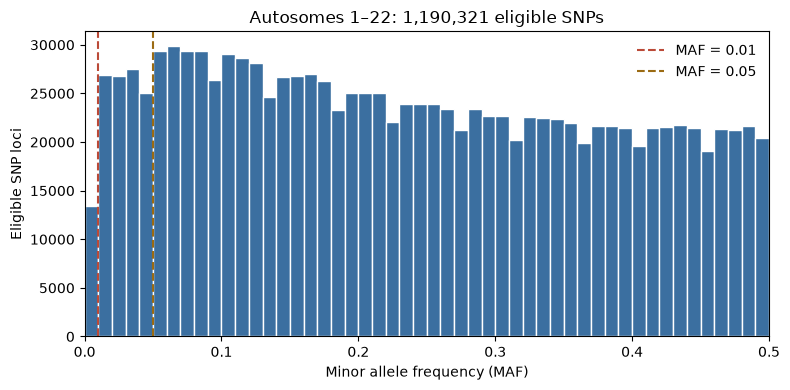

In [9]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(snps['MAF'], bins=50, range=(0, 0.5), color='#3B6FA0', edgecolor='white')
ax.axvline(0.01, color='#BB4A38', linestyle='--', label='MAF = 0.01')
ax.axvline(0.05, color='#9B6B13', linestyle='--', label='MAF = 0.05')
ax.set(xlabel='Minor allele frequency (MAF)', ylabel='Eligible SNP loci',
       title=f'Autosomes 1–22: {len(snps):,} eligible SNPs', xlim=(0, 0.5))
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

### Task 3: Read and Match Sample IDs

Compare the `.fam` `IID` values with the sample columns in the expression header. Only the header is read.

In [10]:
fam_columns = ['FID', 'IID', 'Father', 'Mother', 'Sex', 'Phenotype']
genotype_samples = pd.read_csv(f'{prefixes[1]}.fam', sep=r'\s+', header=None,
                               names=fam_columns, dtype=str)
genotype_ids = genotype_samples['IID'].tolist()
with expression_file.open() as handle:
    header = handle.readline().rstrip('\r\n').split('\t')
assert header[:4] == ['TargetID', 'Gene_Symbol', 'Chr', 'Coord']
expression_ids = header[4:]

duplicates = pd.Series({'Genotype extra IID rows': len(genotype_ids) - len(set(genotype_ids)),
                        'Expression extra IID columns': len(expression_ids) - len(set(expression_ids))})
display(duplicates.to_frame('Duplicates'))
assert duplicates.eq(0).all(), 'Resolve duplicate IDs before creating a sample alignment.'

consistent_fams = all(
    pd.read_csv(f'{prefix}.fam', sep=r'\s+', header=None, usecols=[1], dtype=str)[1].tolist()
    == genotype_ids for prefix in prefixes.values())
assert consistent_fams, 'FAM sample IDs or their ordering differ across chromosomes.'
print('Individual IDs and order match across all 22 chromosomes:', consistent_fams)
display(genotype_samples[['FID', 'IID']].head())
print('First expression sample IDs:', expression_ids[:5])

,Duplicates
Genotype extra IID rows,0
Expression extra IID columns,0


Individual IDs and order match across all 22 chromosomes: True


,FID,IID
0,HG00096,HG00096
1,HG00097,HG00097
2,HG00099,HG00099
3,HG00101,HG00101
4,HG00102,HG00102


First expression sample IDs: ['HG00096', 'HG00097', 'HG00099', 'HG00100', 'HG00101']


### Task 3: Interpret the Overlap

Set operations give the people in both datasets and in only one. The saved table keeps each person's position in both files.

In [11]:
genotype_set, expression_set = set(genotype_ids), set(expression_ids)
matching = genotype_set & expression_set
genotype_only = genotype_set - expression_set
expression_only = expression_set - genotype_set
overlap = pd.Series({'Genotype individuals': len(genotype_set),
                     'Expression individuals': len(expression_set),
                     'Matching individuals': len(matching),
                     'Genotype only': len(genotype_only),
                     'Expression only': len(expression_only)})
display(overlap.to_frame('Individuals'))
assert len(matching) + len(genotype_only) == len(genotype_set)
assert len(matching) + len(expression_only) == len(expression_set)

alignment = genotype_samples.loc[genotype_samples['IID'].isin(matching), ['FID', 'IID']].copy()
alignment['Genotype_row_0based'] = alignment.index
expression_positions = {iid: column for column, iid in enumerate(header[4:], start=4)}
alignment['Expression_column_0based'] = alignment['IID'].map(expression_positions)
alignment_path = results_dir / 'matched_sample_ids.tsv'
alignment_text = alignment.to_csv(sep='\t', index=False)
if not alignment_path.exists() or alignment_path.read_text() != alignment_text:
    alignment_path.write_text(alignment_text)
display(alignment.head())
print('Matched ID alignment:', alignment_path)

,Individuals
Genotype individuals,489
Expression individuals,462
Matching individuals,344
Genotype only,145
Expression only,118


,FID,IID,Genotype_row_0based,Expression_column_0based
0,HG00096,HG00096,0,4
1,HG00097,HG00097,1,5
2,HG00099,HG00099,2,6
3,HG00101,HG00101,3,8
4,HG00102,HG00102,4,9


Matched ID alignment: data/week2_results/matched_sample_ids.tsv


**Findings:** see Week 2 in [weekly_tasks_results.md](../weekly_tasks_results.md).

# Week 3 — cis-eQTL Mapping

Test SNPs near one gene, **PARK7**, with a separate additive regression for each SNP ([assignment](https://tiffanyamariuta.github.io/capstone-genetic-risk-prediction/weeks/03-eQTL-discovery/)):

$$Y_i = \beta_0 + \beta_1G_i + \epsilon_i,$$

where $Y_i$ is expression and $G_i$ is 0, 1, or 2 copies of the counted allele. PARK7 was chosen before looking at its association results.

In [12]:
from pathlib import Path
import subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import linregress, false_discovery_control

gene_id = 'ENSG00000116288.8'
genotype_prefix = Path('data/LDREF/1000G.EUR.1')
expression_path = Path('data/GD462.GeneQuantRPKM.50FN.samplename.resk10.txt')
week3_dir = Path('data/week3_results')
week3_dir.mkdir(parents=True, exist_ok=True)

annotation = pd.read_csv('data/gene_annot.txt.gz', sep='\t')
display(annotation.head(3))
local_gene = annotation.loc[annotation['SYM'].eq(gene_id.rsplit('.', 1)[0])]
display(local_gene)

,ID,CHR,START,STOP,SYM,TYPE
0,DDX11L1,1,11868,13052,ENSG00000223972,transcribed_unprocessed_pseudogene
1,OR4F5,1,69090,70008,ENSG00000186092,protein_coding
2,FAM87B,1,817370,819834,ENSG00000177757,lincRNA


,ID,CHR,START,STOP,SYM,TYPE
115,PARK7,1,7954290,7985505,ENSG00000116288,protein_coding


The local annotation's PARK7 coordinates are GRCh38, but our genotypes are GRCh37. We use the [GENCODE v12 GRCh37](https://www.gencodegenes.org/human/release_12.html) record instead, saved as `data/week3_results/PARK7.gencode12.GRCh37.gtf`.

In [13]:
gene_record = pd.read_csv(week3_dir / 'PARK7.gencode12.GRCh37.gtf',
                          sep='\t', comment='#', header=None).iloc[0]
assert gene_record[2] == 'gene' and f'gene_id "{gene_id}"' in gene_record[8]
gene_chr = int(gene_record[0].removeprefix('chr'))
gene_start, gene_end = int(gene_record[3]), int(gene_record[4])
print(f'PARK7, GRCh37: chr{gene_chr}:{gene_start:,}–{gene_end:,}; strand {gene_record[6]}')

bim_chr1 = pd.read_csv(f'{genotype_prefix}.bim', sep=r'\s+', header=None,
                       names=['Chromosome', 'SNP_ID', 'CM', 'Position', 'A1', 'A2'])
reference_positions = pd.Series({'rs3094315': 752566, 'rs1048488': 760912},
                                name='Ensembl_GRCh37_position')
build_check = pd.concat([reference_positions,
    bim_chr1.set_index('SNP_ID')['Position'].loc[reference_positions.index]], axis=1)
assert build_check.iloc[:, 0].equals(build_check.iloc[:, 1])
display(build_check)

PARK7, GRCh37: chr1:8,014,351–8,045,565; strand +


,Ensembl_GRCh37_position,Position
rs3094315,752566,752566
rs1048488,760912,760912


### Defining the cis-Window

**Cis** here means the gene body plus 500 kb on either side, using 1-based inclusive positions. PLINK `--export A` writes allele dosages for biallelic SNPs in the window.

In [14]:
cis_start = max(1, gene_start - 500000)
cis_end = gene_end + 500000
cis_prefix = week3_dir / 'PARK7_cis'
command = [PLINK2, '--bfile', str(genotype_prefix),
           '--chr', str(gene_chr), '--from-bp', str(cis_start), '--to-bp', str(cis_end),
           '--snps-only', 'just-acgt', '--min-alleles', '2', '--max-alleles', '2',
           '--export', 'A', '--threads', '2', '--memory', '1024', '--out', str(cis_prefix)]
print(' '.join(command))
subprocess.run(command, check=True, capture_output=True, text=True)
raw_genotypes = pd.read_csv(f'{cis_prefix}.raw', sep=r'\s+', dtype={'FID': str, 'IID': str})
dosage_columns = raw_genotypes.columns[6:].tolist()
variant_info = pd.DataFrame([c.rsplit('_', 1) for c in dosage_columns],
                            columns=['SNP_ID', 'Counted_allele'])
variant_info['Dosage_column'] = dosage_columns
variant_info = variant_info.merge(bim_chr1.drop(columns='CM'), on='SNP_ID', validate='one_to_one')
assert variant_info['Position'].between(cis_start, cis_end).all()
print('Candidate SNPs extracted:', len(variant_info))
display(variant_info[['SNP_ID', 'Position', 'Counted_allele']].head())

./plink2_binary --bfile data/LDREF/1000G.EUR.1 --chr 1 --from-bp 7514351 --to-bp 8545565 --snps-only just-acgt --min-alleles 2 --max-alleles 2 --export A --threads 2 --memory 1024 --out data/week3_results/PARK7_cis
Candidate SNPs extracted: 437


,SNP_ID,Position,Counted_allele
0,rs1880808,7514621,A
1,rs1857161,7518009,C
2,rs17030898,7518513,G
3,rs1725236,7518641,G
4,rs17030902,7518698,T


### Matching Individuals and Preparing Genotypes

Read only the PARK7 expression row, using values as provided, and put genotypes and expression in the same ID order.

In [15]:
with expression_path.open() as handle:
    expression_header = handle.readline().rstrip('\r\n').split('\t')
    gene_rows = [line.rstrip('\r\n').split('\t') for line in handle
                 if line.split('\t', 1)[0] == gene_id]
if len(gene_rows) != 1:
    raise ValueError(f'Expected one expression row for {gene_id}; found {len(gene_rows)}.')
assert expression_header[:4] == ['TargetID', 'Gene_Symbol', 'Chr', 'Coord']
assert int(gene_rows[0][2]) == gene_chr and gene_start <= int(gene_rows[0][3]) <= gene_end
gene_expression = pd.Series(pd.to_numeric(gene_rows[0][4:]),
                            index=expression_header[4:], name='Expression')

matched_ids = pd.read_csv('data/week2_results/matched_sample_ids.tsv', sep='\t', dtype=str)['IID']
assert matched_ids.is_unique and raw_genotypes['IID'].is_unique and gene_expression.index.is_unique
assert set(matched_ids) == set(raw_genotypes['IID']) & set(gene_expression.index)
genotypes = raw_genotypes.set_index('IID').loc[matched_ids, dosage_columns]
expression = gene_expression.loc[genotypes.index]
assert genotypes.index.equals(expression.index)
print('Matched individuals:', len(expression))
display(expression.head().to_frame())

Matched individuals: 344


,Expression
IID,
HG00096,231.071502
HG00097,193.003392
HG00099,182.891284
HG00101,226.067465
HG00102,223.253451


QC keeps two distinct A/C/G/T alleles and needs variation and at least 3 observations. Missing genotypes are dropped per SNP, not imputed, and no MAF cutoff is added. Results name the counted allele.

In [16]:
finite_expression = np.isfinite(expression)
genotypes = genotypes.loc[finite_expression]
expression = expression.loc[finite_expression]
ordinary_snp = (variant_info['A1'].isin(list('ACGT'))
                & variant_info['A2'].isin(list('ACGT'))
                & variant_info['A1'].ne(variant_info['A2']))
ordinary_columns = variant_info.loc[ordinary_snp, 'Dosage_column']
eligible_columns = [c for c in ordinary_columns
                    if genotypes[c].count() >= 3 and genotypes[c].nunique() > 1]
qc_summary = pd.Series({
    'Candidate SNPs': len(variant_info),
    'Excluded non-SNP allele annotations': int((~ordinary_snp).sum()),
    'Excluded constant / insufficient-data SNPs': len(ordinary_columns) - len(eligible_columns),
    'SNPs retained for regression': len(eligible_columns),
    'People excluded for expression missingness': int((~finite_expression).sum()),
    'Missing genotype calls in matched people': int(genotypes.isna().sum().sum()),
})
display(qc_summary.to_frame('Count'))

,Count
Candidate SNPs,437
Excluded non-SNP allele annotations,0
Excluded constant / insufficient-data SNPs,0
SNPs retained for regression,437
People excluded for expression missingness,0
Missing genotype calls in matched people,0


### Running SNP–Expression Regressions

Fit one [`linregress`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.linregress.html) per SNP, with no covariates, and show the 10 smallest p-values.

In [17]:
regression_rows = []
for column in eligible_columns:
    paired = pd.concat([genotypes[column].rename('Genotype'), expression], axis=1).dropna()
    fit = linregress(paired['Genotype'], paired['Expression'])
    info = variant_info.loc[variant_info['Dosage_column'].eq(column)].iloc[0]
    regression_rows.append({
        'SNP_ID': info['SNP_ID'], 'Chromosome': info['Chromosome'],
        'Position': info['Position'], 'Counted_allele': info['Counted_allele'],
        'Beta': fit.slope, 'SE': fit.stderr, 'Intercept': fit.intercept,
        'P_value': fit.pvalue, 'N': len(paired),
    })
eqtl_results = pd.DataFrame(regression_rows).sort_values('P_value').reset_index(drop=True)
assert len(eqtl_results) == len(eligible_columns)
display(eqtl_results.drop(columns='Intercept').head(10))

,SNP_ID,Chromosome,Position,Counted_allele,Beta,SE,P_value,N
0,rs11805932,1,7521479,G,-19.607803,5.905207,0.000996,344
1,rs228651,1,7911099,C,9.331693,2.870793,0.001266,344
2,rs732401,1,7529244,G,-49.651683,16.800728,0.003340,344
3,rs1725260,1,7562339,G,8.486882,2.897645,0.003630,344
4,rs2859389,1,7920423,C,8.726867,3.049773,0.004476,344
5,rs1616122,1,7521585,T,-7.758644,2.717492,0.004565,344
6,rs1193185,1,7538437,T,7.853753,2.776720,0.004953,344
7,rs1725241,1,7567618,C,8.269301,2.982004,0.005857,344
8,rs1040395,1,7952203,G,7.709127,2.822791,0.006641,344
9,rs1149331,1,7528669,A,-7.521550,2.758456,0.006726,344


### Multiple-Testing Correction

Apply [Benjamini–Hochberg](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.false_discovery_control.html) and Bonferroni across all tested SNPs for PARK7.

In [18]:
number_of_tests = len(eqtl_results)
eqtl_results['P_BH'] = false_discovery_control(eqtl_results['P_value'], method='bh')
eqtl_results['P_Bonferroni'] = (eqtl_results['P_value'] * number_of_tests).clip(upper=1)
significance = pd.Series({
    'Nominal p < 0.05': int(eqtl_results['P_value'].lt(0.05).sum()),
    'BH FDR < 0.05': int(eqtl_results['P_BH'].lt(0.05).sum()),
    'Bonferroni-adjusted p < 0.05': int(eqtl_results['P_Bonferroni'].lt(0.05).sum()),
})
display(significance.to_frame('SNPs'))
print(f'Bonferroni raw p-value threshold: {0.05 / number_of_tests:.8g}')
eqtl_results.to_csv(week3_dir / 'PARK7_cis_eqtl.tsv', sep='\t', index=False)

,SNPs
Nominal p < 0.05,44
BH FDR < 0.05,0
Bonferroni-adjusted p < 0.05,0


Bonferroni raw p-value threshold: 0.00011441648


### Visualizing the Associations

Each point is a SNP at its GRCh37 position. The shaded band is the gene body.

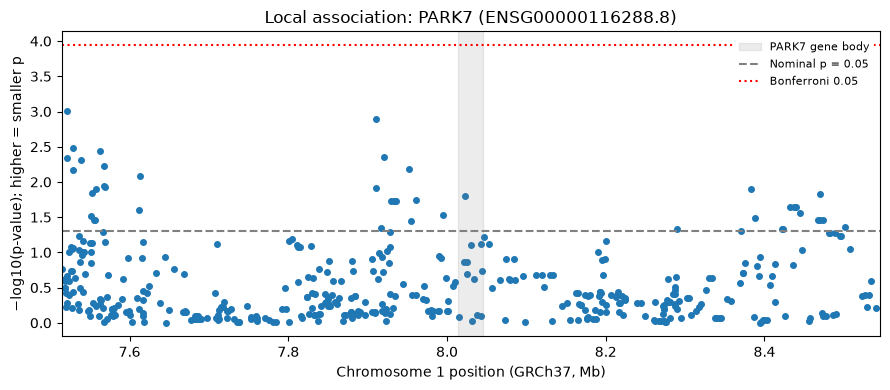

In [19]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.scatter(eqtl_results['Position'] / 1e6, -np.log10(eqtl_results['P_value']), s=16)
ax.axvspan(gene_start / 1e6, gene_end / 1e6, alpha=0.15, color='gray', label='PARK7 gene body')
ax.axhline(-np.log10(0.05), color='gray', linestyle='--', label='Nominal p = 0.05')
ax.axhline(-np.log10(0.05 / number_of_tests), color='red', linestyle=':', label='Bonferroni 0.05')
ax.set(xlabel='Chromosome 1 position (GRCh37, Mb)', ylabel='−log10(p-value); higher = smaller p',
       title=f'Local association: PARK7 ({gene_id})', xlim=(cis_start / 1e6, cis_end / 1e6))
ax.legend(fontsize=8, facecolor='white', framealpha=1, edgecolor='none')
fig.tight_layout()
fig.savefig(week3_dir / 'PARK7_local_association.png', dpi=180)
plt.show()

PARK7 expression by copies of **G at rs11805932**, the strongest nominal SNP. Each point is a person, and horizontal jitter only separates overlapping points.

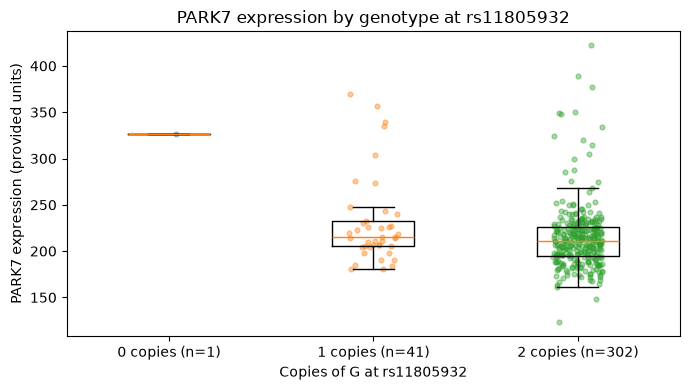

In [20]:
lead = eqtl_results.iloc[0]
lead_column = variant_info.loc[variant_info['SNP_ID'].eq(lead['SNP_ID']), 'Dosage_column'].iloc[0]
lead_data = pd.concat([genotypes[lead_column].rename('Genotype'), expression], axis=1).dropna()
groups = [lead_data.loc[lead_data['Genotype'].eq(d), 'Expression'] for d in [0, 1, 2]]
fig, ax = plt.subplots(figsize=(7, 4))
ax.boxplot(groups, positions=[0, 1, 2], widths=0.4, showfliers=False,
           tick_labels=[f'{d} copies (n={len(group)})' for d, group in enumerate(groups)])
rng = np.random.default_rng(0)
for dosage, group in enumerate(groups):
    ax.scatter(dosage + rng.uniform(-0.12, 0.12, len(group)), group, s=12, alpha=0.4)
ax.set(xlabel=f'Copies of {lead["Counted_allele"]} at {lead["SNP_ID"]}',
       ylabel='PARK7 expression (provided units)', title=f'PARK7 expression by genotype at {lead["SNP_ID"]}')
fig.tight_layout()
fig.savefig(week3_dir / 'PARK7_lead_genotype_expression.png', dpi=180)
plt.show()

**Findings:** see Week 3 in [weekly_tasks_results.md](../weekly_tasks_results.md).

# Week 4 — Chromosome-Wide eQTL Analysis and Genetic Prediction

Task 1 repeats Week 3's regression for every expressed chromosome 1 gene. Tasks 2–3 ask whether training-derived SNP effects predict expression in new people ([assignment](https://tiffanyamariuta.github.io/capstone-genetic-risk-prediction/weeks/04-reinforcement-eQTL/)).

The all-person results are descriptive: they never supply prediction weights or choose the prediction gene.

### Task 1: cis-eQTL Mapping Across Chromosome 1

We use expression as provided, Week 2's matched IDs, [GENCODE v12 on GRCh37](https://www.gencodegenes.org/human/release_12.html), and gene body ±500 kb. All expressed gene types are included.

In [21]:
from pathlib import Path
import gzip
import subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import linregress, pearsonr, false_discovery_control

w4 = Path('data/week4_results')
w4.mkdir(parents=True, exist_ok=True)
w4_prefix = 'data/LDREF/1000G.EUR.1'
w4_samples = pd.read_csv('data/week2_results/matched_sample_ids.tsv', sep='\t', dtype=str)
w4_ids = w4_samples['IID'].tolist()
w4_column = dict(zip(w4_ids, w4_samples['FID'] + '_' + w4_samples['IID']))
w4_samples[['FID', 'IID']].to_csv(w4 / 'matched.keep', sep='\t', index=False, header=False)

expression_chunks = pd.read_csv('data/GD462.GeneQuantRPKM.50FN.samplename.resk10.txt',
    sep='\t', usecols=['TargetID', 'Chr', 'Coord', *w4_ids], dtype={'Chr': str}, chunksize=2000)
w4_expression = pd.concat([c.loc[c['Chr'].eq('1')] for c in expression_chunks]).set_index('TargetID')
fam_ids = pd.read_csv(f'{w4_prefix}.fam', sep=r'\s+', header=None, dtype=str)[1]
expression_header = pd.read_csv('data/GD462.GeneQuantRPKM.50FN.samplename.resk10.txt', sep='\t', nrows=0).columns[4:]
assert set(w4_ids) == set(fam_ids) & set(expression_header) and w4_samples['IID'].is_unique
print('Matched individuals:', len(w4_ids), '| Expressed chromosome 1 genes:', len(w4_expression))

Matched individuals: 344 | Expressed chromosome 1 genes: 2479


In [22]:
gtf = pd.read_csv(w4 / 'chr1.gencode12.GRCh37.gtf', sep='\t', comment='#', header=None)
w4_annotation = pd.DataFrame({
    'Gene_ID': gtf[8].str.extract(r'gene_id "([^"]+)"')[0],
    'Symbol': gtf[8].str.extract(r'gene_name "([^"]+)"')[0],
    'Start': gtf[3], 'End': gtf[4], 'Strand': gtf[6],
}).set_index('Gene_ID')
w4_genes = w4_annotation.reindex(w4_expression.index).copy()
w4_genes['Cis_start'] = (w4_genes['Start'] - 500000).clip(lower=1)
w4_genes['Cis_end'] = w4_genes['End'] + 500000
y_values = w4_expression[w4_ids].to_numpy(float)
w4_genes['Reason'] = 'Eligible'
w4_genes.loc[w4_genes['Start'].isna(), 'Reason'] = 'No exact-version GRCh37 annotation'
outside = ~w4_expression['Coord'].between(w4_genes['Start'], w4_genes['End'])
w4_genes.loc[outside & w4_genes['Start'].notna(), 'Reason'] = 'Expression coordinate outside gene body'
w4_genes.loc[np.isfinite(y_values).sum(axis=1) < 3, 'Reason'] = 'Fewer than 3 expression observations'
w4_genes.loc[np.nanstd(y_values, axis=1) == 0, 'Reason'] = 'Constant expression'
display(w4_genes['Reason'].value_counts().to_frame('Genes'))

,Genes
Reason,
Eligible,2479


`fit_cis` runs Week 3's regression on each SNP row, reading the export 2,000 rows at a time. No MAF or Hardy–Weinberg cutoff is added.

In [23]:
export_command = [PLINK2, '--bfile', w4_prefix, '--keep', str(w4 / 'matched.keep'),
    '--snps-only', 'just-acgt', '--min-alleles', '2', '--max-alleles', '2',
    '--export', 'Av', '--threads', '2', '--memory', '1024', '--out', str(w4 / 'chr1_matched')]
if not (w4 / 'chr1_matched.traw').exists():
    subprocess.run(export_command, check=True, capture_output=True, text=True)
assert set(w4_column.values()).issubset(pd.read_csv(w4 / 'chr1_matched.traw', sep=r'\s+', nrows=0).columns)

def fit_cis(variants, ids, y):
    """Week 3's additive regressions, one SNP per row; use only the supplied people."""
    ids = [i for i in ids if np.isfinite(y.loc[i])]
    g = variants[[w4_column[i] for i in ids]].to_numpy(float)
    n = np.isfinite(g).sum(axis=1)
    ordinary = variants['COUNTED'].isin(list('ACGT')) & variants['ALT'].isin(list('ACGT'))
    ordinary &= variants['COUNTED'].ne(variants['ALT'])
    keep = ordinary.to_numpy() & (n >= 3) & (np.nanstd(g, axis=1) > 0)
    result = variants.loc[keep, ['CHR', 'SNP', 'POS', 'COUNTED']].copy()
    if result.empty:
        return result.assign(BETA=[], SE=[], P=[], N=[])
    fit = linregress(g[keep], y.loc[ids].to_numpy(dtype=float)[None, :], axis=1, nan_policy='omit')
    return result.assign(BETA=fit.slope, SE=fit.stderr, P=fit.pvalue, N=n[keep])

In [24]:
association_path = w4 / 'chr1_cis_eqtl.tsv.gz'
eligible_genes = w4_genes.loc[w4_genes['Reason'].eq('Eligible')]

def map_chr1(output_path, ids):
    """Run fit_cis for every eligible chromosome 1 gene, using only the supplied people."""
    written = False
    with gzip.open(output_path, 'wt') as output:
        for block in pd.read_csv(w4 / 'chr1_matched.traw', sep=r'\s+', chunksize=2000):
            assert block['CHR'].eq(1).all()
            overlapping = eligible_genes.loc[(eligible_genes.Cis_start <= block.POS.max())
                                             & (eligible_genes.Cis_end >= block.POS.min())]
            for gene, region in overlapping.iterrows():
                nearby = block.loc[block['POS'].between(region.Cis_start, region.Cis_end)]
                if nearby.empty:
                    continue
                result = fit_cis(nearby, ids, w4_expression.loc[gene, ids])
                if not result.empty:
                    result.insert(0, 'Gene_ID', gene)
                    result.to_csv(output, sep='\t', index=False, header=not written)
                    written = True

map_chr1(association_path, w4_ids)
print('Finished chromosome 1 mapping in all matched individuals.')

Finished chromosome 1 mapping in all matched individuals.


The correction treats every chromosome 1 SNP–gene pair as one testing family. Gene counts are descriptive, not a separate gene-level test.

In [25]:
w4_associations = pd.read_csv(association_path, sep='\t')
w4_associations['P_BH_chr1'] = false_discovery_control(w4_associations['P'], method='bh')
w4_associations['P_Bonferroni_chr1'] = (w4_associations['P'] * len(w4_associations)).clip(upper=1)
w4_associations.to_csv(association_path, sep='\t', index=False, compression='gzip')
gene_summary = w4_associations.groupby('Gene_ID').agg(SNPs=('SNP', 'size'), Min_p=('P', 'min'),
    Min_BH=('P_BH_chr1', 'min'), Min_Bonferroni=('P_Bonferroni_chr1', 'min'))
no_snps = w4_genes['Reason'].eq('Eligible') & ~w4_genes.index.isin(gene_summary.index)
w4_genes.loc[no_snps, 'Reason'] = 'No eligible cis-SNPs'
gene_summary.to_csv(w4 / 'chr1_gene_summary.tsv', sep='\t')
w4_genes.loc[~w4_genes['Reason'].eq('Eligible')].to_csv(w4 / 'excluded_genes.tsv', sep='\t')
mapping_summary = pd.Series({
    'Expressed chromosome 1 genes': len(w4_expression), 'Genes analyzed': len(gene_summary),
    'SNP–gene tests': len(w4_associations), 'Nominal SNP–gene hits': int(w4_associations.P.lt(0.05).sum()),
    'BH chromosome-wide hits': int(w4_associations.P_BH_chr1.lt(0.05).sum()),
    'Bonferroni chromosome-wide hits': int(w4_associations.P_Bonferroni_chr1.lt(0.05).sum()),
    'Genes with a nominal hit': int(gene_summary.Min_p.lt(0.05).sum()),
    'Genes with a chromosome-wide BH hit': int(gene_summary.Min_BH.lt(0.05).sum()),
    'Genes with a chromosome-wide Bonferroni hit': int(gene_summary.Min_Bonferroni.lt(0.05).sum()),
})
display(mapping_summary.to_frame('Count'))
display(gene_summary['SNPs'].describe().to_frame('SNPs tested per gene'))
display(w4_genes['Reason'].value_counts().to_frame('Genes'))

,Count
Expressed chromosome 1 genes,2479
Genes analyzed,2443
SNP–gene tests,1004372
Nominal SNP–gene hits,86234
BH chromosome-wide hits,10621
Bonferroni chromosome-wide hits,2446
Genes with a nominal hit,2368
Genes with a chromosome-wide BH hit,746
Genes with a chromosome-wide Bonferroni hit,183


,SNPs tested per gene
count,2443.000000
mean,411.122391
std,143.934503
min,1.000000
25%,335.000000
50%,422.000000
75%,497.000000
max,1394.000000


,Genes
Reason,
Eligible,2443
No eligible cis-SNPs,36


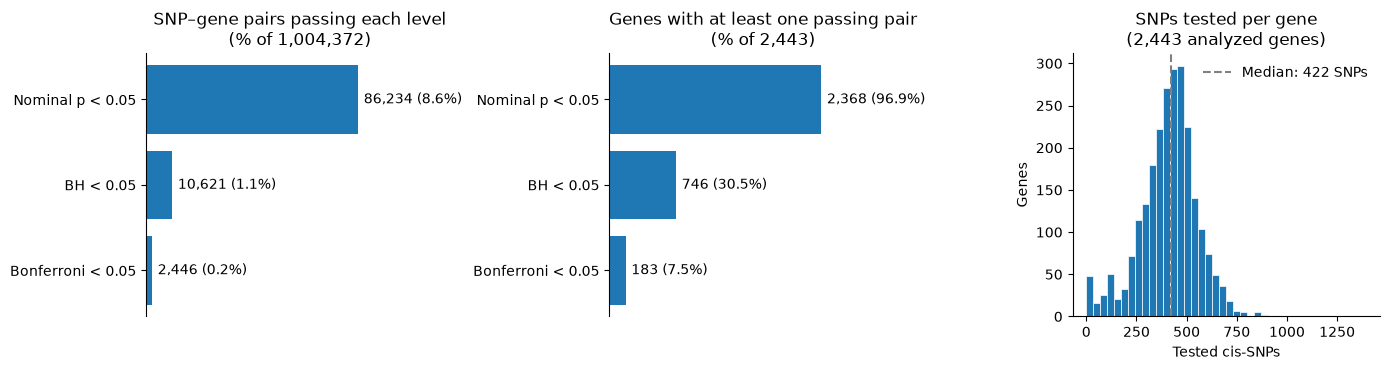

In [26]:
levels = ['Nominal p < 0.05', 'BH < 0.05', 'Bonferroni < 0.05']
panels = [('SNP–gene pairs passing each level', len(w4_associations),
           ['Nominal SNP–gene hits', 'BH chromosome-wide hits', 'Bonferroni chromosome-wide hits']),
          ('Genes with at least one passing pair', len(gene_summary),
           ['Genes with a nominal hit', 'Genes with a chromosome-wide BH hit', 'Genes with a chromosome-wide Bonferroni hit'])]
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, (title, total, keys) in zip(axes, panels):
    values = mapping_summary[keys].to_numpy()
    bars = ax.barh(levels, values, color='C0')
    ax.bar_label(bars, labels=[f'{v:,} ({v / total:.1%})' for v in values], padding=4)
    ax.invert_yaxis()
    ax.set_xlim(0, values.max() * 1.45)
    ax.set_title(f'{title}\n(% of {total:,})')
    ax.xaxis.set_visible(False)
    ax.spines['bottom'].set_visible(False)
median_snps = gene_summary['SNPs'].median()
axes[2].hist(gene_summary['SNPs'], bins=40, color='C0', edgecolor='white', linewidth=0.5)
axes[2].axvline(median_snps, linestyle='--', color='gray', label=f'Median: {median_snps:.0f} SNPs')
axes[2].set(title=f'SNPs tested per gene\n({len(gene_summary):,} analyzed genes)', xlabel='Tested cis-SNPs', ylabel='Genes')
axes[2].legend(frameon=False)
for ax in axes:
    ax.spines[['top', 'right']].set_visible(False)
fig.tight_layout()
fig.savefig(w4 / 'chr1_mapping_summary.png', dpi=180)
plt.show()

### Task 2: Pruning/Clumping and Thresholding (P+T)

We adapt the [PRS tutorial](https://choishingwan.github.io/PRS-Tutorial/plink/) to expression. The score is $S_i=\sum_j\hat\beta_jG_{ij}$, with expression betas as weights. It is a genetic expression score, not a disease-risk score.

Clumping keeps the lowest-p SNP and removes neighbors within **250 kb** at $r^2>0.1$, with LD estimated in training people. Inclusive p-value cutoffs **1, 0.05, 0.01, 0.001, 0.00001** then select nested SNP sets.

### Task 3: The Three-Step Prediction Procedure

| Step | Who | What happens |
|---|---|---|
| 1 | Random 80% (275 people) | Estimate cis-eQTL effects, LD clumps, and calibration |
| 2 | Half of the remainder (34 people) | Compare the five p-value thresholds |
| 3 | Other half (35 people) | Measure final accuracy once with the frozen model |

The 344 matched IDs are shuffled with seed **42** before any prediction effects are estimated.

In [27]:
shuffled = np.random.default_rng(42).permutation(w4_ids)
n_train = int(0.8 * len(shuffled))
n_validation = (len(shuffled) - n_train) // 2
train_ids = shuffled[:n_train].tolist()
validation_ids = shuffled[n_train:n_train + n_validation].tolist()
test_ids = shuffled[n_train + n_validation:].tolist()
assert not (set(train_ids) & set(validation_ids) or set(train_ids) & set(test_ids)
            or set(validation_ids) & set(test_ids))
for name, ids in [('train', train_ids), ('validation', validation_ids), ('test', test_ids)]:
    w4_samples.set_index('IID').loc[ids].reset_index()[['FID', 'IID']].to_csv(
        w4 / f'{name}.keep', sep='\t', index=False, header=False)
assert (len(train_ids), len(validation_ids), len(test_ids)) == (275, 34, 35)
split_sizes = pd.Series({'Training': len(train_ids), 'Validation': len(validation_ids), 'Testing': len(test_ids)})
display(split_sizes.to_frame('Individuals'))

,Individuals
Training,275
Validation,34
Testing,35


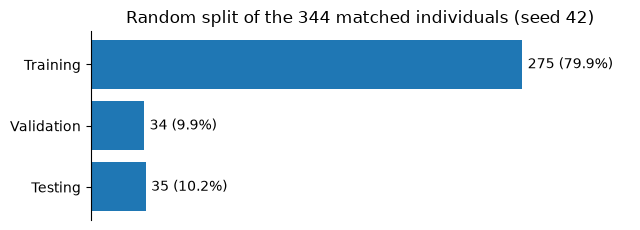

In [28]:
fig, ax = plt.subplots(figsize=(6.5, 2.4))
bars = ax.barh(split_sizes.index, split_sizes, color='C0')
ax.bar_label(bars, labels=[f'{n} ({n / len(w4_ids):.1%})' for n in split_sizes], padding=4)
ax.invert_yaxis()
ax.set_xlim(0, split_sizes.max() * 1.25)
ax.set_title(f'Random split of the {len(w4_ids)} matched individuals (seed 42)')
ax.xaxis.set_visible(False)
ax.spines[['top', 'right', 'bottom']].set_visible(False)
fig.tight_layout()
fig.savefig(w4 / 'sample_split.png', dpi=180)
plt.show()

### Selecting the Gene With Training-Only Results

Task 1 included validation and test people, so choosing from it would leak information. We repeat the scan in the **275 training people** and take the gene with the smallest p-value. Ties go to the first Ensembl ID.

In [29]:
training_path = w4 / 'chr1_training_cis_eqtl.tsv.gz'
map_chr1(training_path, train_ids)
training_scan = pd.read_csv(training_path, sep='\t')
training_scan['P_Bonferroni_train'] = (training_scan['P'] * len(training_scan)).clip(upper=1)
training_scan.to_csv(training_path, sep='\t', index=False, compression='gzip')
training_genes = training_scan.groupby('Gene_ID').agg(Cis_SNPs=('SNP', 'size'), Min_p=('P', 'min'),
    Min_Bonferroni=('P_Bonferroni_train', 'min')).join(w4_annotation[['Symbol', 'Start', 'End']])
training_genes = training_genes.reset_index().sort_values(['Min_p', 'Gene_ID'], ignore_index=True)
training_genes.to_csv(w4 / 'chr1_training_gene_summary.tsv', sep='\t', index=False)
selected = training_genes.iloc[0]
assert selected['Min_Bonferroni'] < 0.05
selected.to_frame().T.to_csv(w4 / 'selected_gene.tsv', sep='\t', index=False)

print('Training SNP–gene tests:', len(training_scan), '| Genes analyzed:', len(training_genes),
      '| Genes with a Bonferroni-significant training SNP:', int(training_genes['Min_Bonferroni'].lt(0.05).sum()))
display(training_genes.head(5))
print(f"Selected gene: {selected['Symbol']} ({selected['Gene_ID']})")
print(f"GRCh37 coordinates: chr1:{selected['Start']:,}–{selected['End']:,}")
print(f"Eligible training cis-SNPs: {selected['Cis_SNPs']}")
print(f"Strongest training p-value: {selected['Min_p']:.3e}")
print(f"Bonferroni-adjusted p-value: {selected['Min_Bonferroni']:.3e}")

Training SNP–gene tests: 1004175 | Genes analyzed: 2443 | Genes with a Bonferroni-significant training SNP: 143


,Gene_ID,Cis_SNPs,Min_p,Min_Bonferroni,Symbol,Start,End
0,ENSG00000198468.2,414,2.921854e-86,2.934053e-80,FLVCR1-AS1,213025450,213031430
1,ENSG00000231581.1,493,5.610195e-56,5.633617e-50,RP5-997D24.5,54690181,54691156
2,ENSG00000218510.3,529,2.878537e-51,2.890555e-45,LINC00339,22351681,22357716
3,ENSG00000142632.10,339,1.809033e-47,1.816585e-41,ARHGEF19,16524349,16539140
4,ENSG00000135778.6,609,1.496773e-37,1.503022e-31,NTPCR,233086351,233114548


Selected gene: FLVCR1-AS1 (ENSG00000198468.2)
GRCh37 coordinates: chr1:213,025,450–213,031,430
Eligible training cis-SNPs: 414
Strongest training p-value: 2.922e-86
Bonferroni-adjusted p-value: 2.934e-80


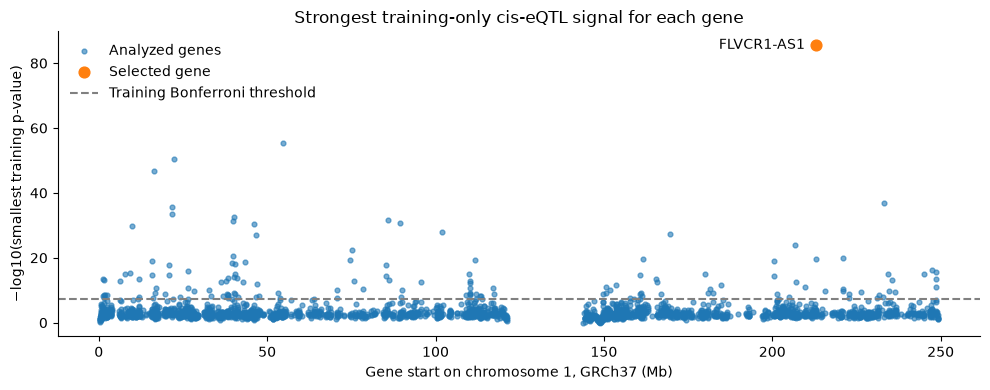

In [30]:
training_bonferroni = 0.05 / len(training_scan)
fig, ax = plt.subplots(figsize=(10, 4))
ax.scatter(training_genes['Start'] / 1e6, -np.log10(training_genes['Min_p']), s=12, alpha=0.6, color='C0', label='Analyzed genes')
ax.scatter(selected['Start'] / 1e6, -np.log10(selected['Min_p']), s=60, color='C1', zorder=3, label='Selected gene')
ax.annotate(selected['Symbol'], (selected['Start'] / 1e6, -np.log10(selected['Min_p'])), xytext=(-8, 0),
    textcoords='offset points', ha='right', va='center')
ax.axhline(-np.log10(training_bonferroni), linestyle='--', color='gray', label='Training Bonferroni threshold')
ax.set(xlabel='Gene start on chromosome 1, GRCh37 (Mb)', ylabel='−log10(smallest training p-value)',
    title='Strongest training-only cis-eQTL signal for each gene')
ax.spines[['top', 'right']].set_visible(False)
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(w4 / 'training_gene_selection.png', dpi=180)
plt.show()

### Step 1: Training cis-eQTL Analysis in the Random 80%

Genotypes are exported for training people only, then tested and clumped. `A1` is the counted allele, not necessarily the minor allele.

In [31]:
gene_id, gene_symbol = selected['Gene_ID'], selected['Symbol']
w4_start, w4_end = max(1, int(selected['Start']) - 500000), int(selected['End']) + 500000
gene_file = lambda suffix: w4 / f'{gene_symbol}_{suffix}'
single_y = w4_expression.loc[gene_id, w4_ids].astype(float)
assert single_y.notna().all()

subprocess.run([PLINK2, '--bfile', w4_prefix, '--keep', str(w4 / 'train.keep'),
    '--chr', '1', '--from-bp', str(w4_start), '--to-bp', str(w4_end),
    '--snps-only', 'just-acgt', '--min-alleles', '2', '--max-alleles', '2',
    '--export', 'Av', '--threads', '2', '--memory', '1024', '--out', str(gene_file('training_cis'))],
    check=True, capture_output=True, text=True)
train_variants = pd.read_csv(gene_file('training_cis.traw'), sep=r'\s+')
train_associations = fit_cis(train_variants, train_ids, single_y).rename(columns={'COUNTED': 'A1'})
train_associations = train_associations[['SNP', 'A1', 'BETA', 'SE', 'P', 'N', 'POS']]
train_path = gene_file('training_eqtl.tsv')
train_associations.to_csv(train_path, sep='\t', index=False)
print(f'{gene_symbol} cis-window: chr1:{w4_start:,}–{w4_end:,}')
display(train_associations.sort_values(['P', 'SNP']).head(10))

clump_command = [PLINK2, '--bfile', w4_prefix, '--keep', str(w4 / 'train.keep'),
    '--clump', str(train_path), '--clump-id-field', 'SNP', '--clump-p-field', 'P',
    '--clump-a1-field', 'A1', '--clump-p1', '1', '--clump-p2', '1',
    '--clump-r2', '0.1', '--clump-kb', '250', '--threads', '2', '--memory', '1024',
    '--out', str(gene_file('training'))]
subprocess.run(clump_command, check=True, capture_output=True, text=True)
clumps = pd.read_csv(gene_file('training.clumps'), sep=r'\s+')
independent = train_associations.loc[train_associations.SNP.isin(clumps['ID'])].copy()
print('Training-eligible SNPs:', len(train_associations), '| Clump index SNPs:', len(independent))

FLVCR1-AS1 cis-window: chr1:212,525,450–213,531,430


,SNP,A1,BETA,SE,P,N,POS
261,rs2279692,T,3.829981,0.130730,2.921854e-86,275,213030534
265,rs963328,T,3.829981,0.130730,2.921854e-86,275,213037661
262,rs1047881,T,3.542849,0.148778,1.367433e-68,275,213031158
273,rs12756625,A,3.542849,0.148778,1.367433e-68,275,213052118
276,rs2291773,T,3.542849,0.148778,1.367433e-68,275,213061030
299,rs11120067,A,-3.234287,0.167702,6.888805e-53,275,213094557
294,rs6679848,T,-3.234287,0.167702,6.888805e-53,275,213092985
295,rs6679938,T,-3.234287,0.167702,6.888805e-53,275,213093033
296,rs6679951,T,-3.234287,0.167702,6.888805e-53,275,213093069
293,rs870547,C,-3.234287,0.167702,6.888805e-53,275,213092639


Training-eligible SNPs: 414 | Clump index SNPs: 47


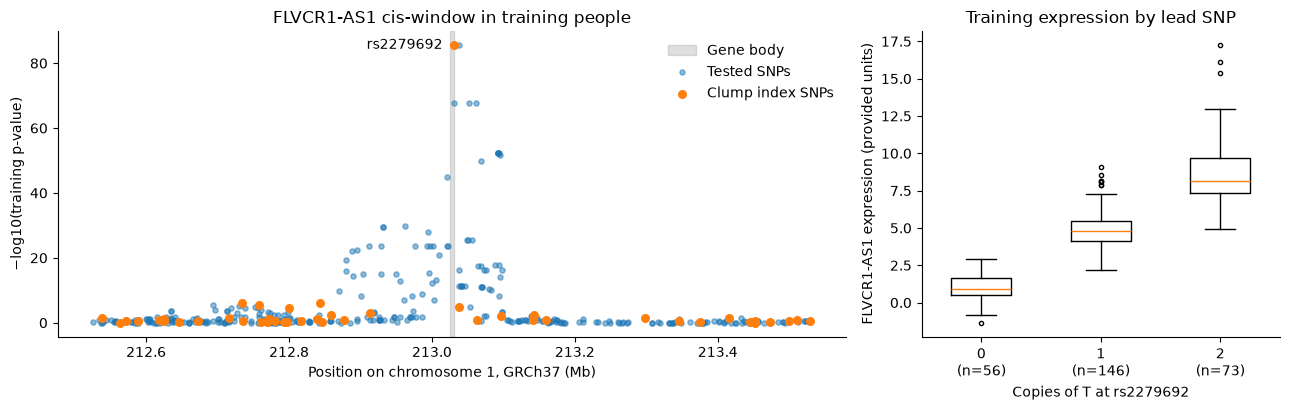

In [32]:
lead_snp = train_associations.sort_values(['P', 'SNP']).iloc[0]
lead_dosage = train_variants.set_index('SNP').loc[lead_snp['SNP'], [w4_column[i] for i in train_ids]].to_numpy(float)
lead_groups = sorted(set(lead_dosage))
fig, (locus_ax, box_ax) = plt.subplots(1, 2, figsize=(13, 4.2), width_ratios=[2.2, 1])
locus_ax.axvspan(selected['Start'] / 1e6, selected['End'] / 1e6, color='gray', alpha=0.25, label='Gene body')
locus_ax.scatter(train_associations['POS'] / 1e6, -np.log10(train_associations['P']), s=14, alpha=0.5, color='C0', label='Tested SNPs')
locus_ax.scatter(independent['POS'] / 1e6, -np.log10(independent['P']), s=30, color='C1', label='Clump index SNPs')
locus_ax.annotate(lead_snp['SNP'], (lead_snp['POS'] / 1e6, -np.log10(lead_snp['P'])), xytext=(-8, 0),
    textcoords='offset points', ha='right', va='center')
locus_ax.set(xlabel='Position on chromosome 1, GRCh37 (Mb)', ylabel='−log10(training p-value)',
    title=f'{gene_symbol} cis-window in training people')
locus_ax.legend(frameon=False)
box_ax.boxplot([single_y.loc[train_ids].to_numpy()[lead_dosage == g] for g in lead_groups],
    tick_labels=[f'{g:.0f}\n(n={(lead_dosage == g).sum()})' for g in lead_groups], widths=0.5,
    medianprops={'color': 'C1'}, flierprops={'markersize': 3})
box_ax.set(xlabel=f"Copies of {lead_snp['A1']} at {lead_snp['SNP']}", ylabel=f'{gene_symbol} expression (provided units)',
    title='Training expression by lead SNP')
for ax in (locus_ax, box_ax):
    ax.spines[['top', 'right']].set_visible(False)
fig.tight_layout()
fig.savefig(gene_file('training_locus.png'), dpi=180)
plt.show()

### Step 2: Choosing the p-Value Threshold in Validation

For each cutoff, fit `expression = intercept + slope × score` on training people and apply it unchanged to validation. We pick the largest **predictive R² = 1 − SSE/SST**, preferring the less stringent cutoff on a tie, and compare it with a training-mean baseline.

In [33]:
thresholds = {'p1': 1.0, 'p005': 0.05, 'p001': 0.01, 'p0001': 0.001, 'p000001': 0.00001}
score_weights = independent[['SNP', 'A1']].copy()
for label, cutoff in thresholds.items():
    score_weights[label] = independent['BETA'].where(independent['P'] <= cutoff, 0)
score_weights.to_csv(gene_file('PT_weights.tsv'), sep='\t', index=False)

def plink_score(weights, keep, out, score_columns):
    """Score the people in a keep file; every person must have every SNP genotyped."""
    subprocess.run([PLINK2, '--bfile', w4_prefix, '--keep', str(keep),
        '--score', str(weights), '1', '2', 'header-read', 'no-mean-imputation', 'cols=+scoresums',
        '--score-col-nums', score_columns, '--threads', '2', '--memory', '1024', '--out', str(out)],
        check=True, capture_output=True, text=True)
    result = pd.read_csv(f'{out}.sscore', sep=r'\s+', dtype={'IID': str}).set_index('IID')
    assert result['ALLELE_CT'].eq(2 * len(pd.read_csv(weights, sep='\t'))).all()
    return result

train_scores = plink_score(gene_file('PT_weights.tsv'), w4 / 'train.keep', gene_file('train'), '3-7')
validation_scores = plink_score(gene_file('PT_weights.tsv'), w4 / 'validation.keep', gene_file('validation'), '3-7')
assert set(train_scores.index) == set(train_ids) and set(validation_scores.index) == set(validation_ids)

In [34]:
def prediction_metrics(observed, predicted):
    r = pearsonr(observed, predicted).statistic if predicted.nunique() > 1 else np.nan
    sst = ((observed - observed.mean()) ** 2).sum()
    return r, r**2, 1 - ((observed - predicted) ** 2).sum() / sst

training_mean = single_y.loc[train_ids].mean()
validation_y = single_y.loc[validation_ids]
baseline_validation_r2 = prediction_metrics(validation_y, pd.Series(training_mean, index=validation_ids))[2]

validation_rows = []
for label, cutoff in thresholds.items():
    count = int(independent['P'].le(cutoff).sum())
    if count == 0:
        intercept, slope = training_mean, 0.0
    else:
        calibration = linregress(train_scores.loc[train_ids, f'{label}_SUM'], single_y.loc[train_ids])
        intercept, slope = calibration.intercept, calibration.slope
    predicted = intercept + slope * validation_scores.loc[validation_ids, f'{label}_SUM']
    r, r2, predictive_r2 = prediction_metrics(validation_y, predicted)
    validation_rows.append({'Threshold': cutoff, 'SNPs': count,
        'Validation_r': r, 'Validation_r2': r2, 'Predictive_R2': predictive_r2,
        'Calibration_intercept': intercept, 'Calibration_slope': slope,
        'Status': 'Training-mean baseline (0 SNPs)' if count == 0 else 'Genetic score'})
validation = pd.DataFrame(validation_rows)
validation.to_csv(gene_file('validation_metrics.tsv'), sep='\t', index=False)
display(validation.drop(columns=['Calibration_intercept', 'Calibration_slope']))

genetic_models = validation.loc[validation['SNPs'] > 0]
best = genetic_models.sort_values(['Predictive_R2', 'Threshold'], ascending=[False, False]).iloc[0]
print('Selected cutoff:', best['Threshold'], '| SNPs in score:', int(best['SNPs']))
print(f"Best genetic validation predictive R²: {best['Predictive_R2']:.4f}")
print(f'Training-mean baseline validation predictive R²: {baseline_validation_r2:.4f}')
print('Best genetic model outperforms baseline in validation:', bool(best['Predictive_R2'] > baseline_validation_r2))
highest_r2 = genetic_models.sort_values(['Validation_r2', 'Threshold'], ascending=[False, False]).iloc[0]
print('For comparison only, squared Pearson r would choose cutoff:', highest_r2['Threshold'])

,Threshold,SNPs,Validation_r,Validation_r2,Predictive_R2,Status
0,1.00000,47,0.676384,0.457496,0.453911,Genetic score
1,0.05000,14,0.710676,0.505060,0.502236,Genetic score
2,0.01000,10,0.723904,0.524037,0.522613,Genetic score
3,0.00100,7,0.765725,0.586335,0.582363,Genetic score
4,0.00001,4,0.783070,0.613198,0.604984,Genetic score


Selected cutoff: 1e-05 | SNPs in score: 4
Best genetic validation predictive R²: 0.6050
Training-mean baseline validation predictive R²: -0.0183
Best genetic model outperforms baseline in validation: True
For comparison only, squared Pearson r would choose cutoff: 1e-05


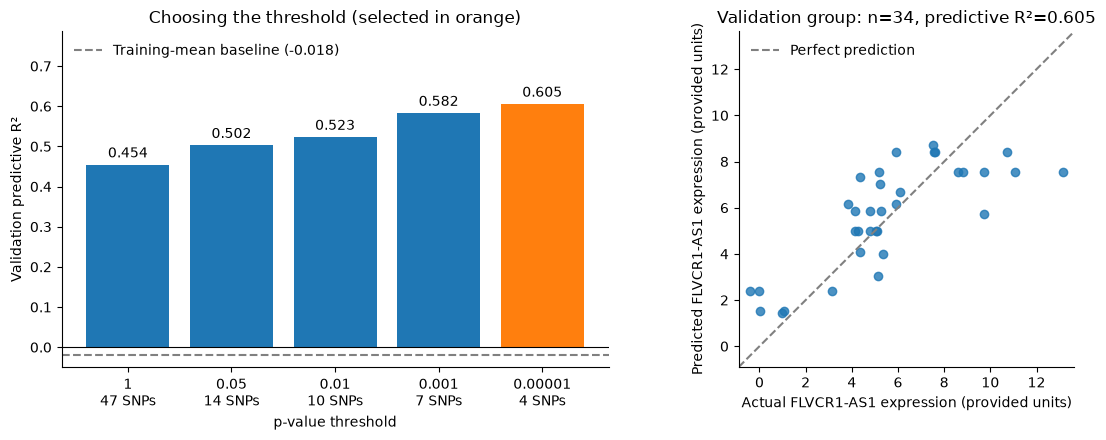

In [35]:
best_label = next(label for label, cutoff in thresholds.items() if cutoff == best['Threshold'])
validation_prediction = best['Calibration_intercept'] + best['Calibration_slope'] * validation_scores.loc[validation_ids, f'{best_label}_SUM']
fig, (r2_ax, scatter_ax) = plt.subplots(1, 2, figsize=(12, 4.5))
tick_names = [f"{t:.5f}".rstrip('0').rstrip('.') + f"\n{n} SNPs" for t, n in zip(validation['Threshold'], validation['SNPs'])]
bars = r2_ax.bar(tick_names, validation['Predictive_R2'], color=['C1' if t == best['Threshold'] else 'C0' for t in validation['Threshold']])
r2_ax.bar_label(bars, fmt='%.3f', padding=3)
r2_ax.axhline(baseline_validation_r2, linestyle='--', color='gray', label=f'Training-mean baseline ({baseline_validation_r2:.3f})')
r2_ax.axhline(0, color='black', linewidth=0.8)
r2_ax.set(xlabel='p-value threshold', ylabel='Validation predictive R²', title='Choosing the threshold (selected in orange)')
r2_ax.legend(frameon=False, loc='upper left')
r2_ax.set_ylim(top=validation['Predictive_R2'].max() * 1.3)
limits = [min(validation_y.min(), validation_prediction.min()) - 0.5, max(validation_y.max(), validation_prediction.max()) + 0.5]
scatter_ax.scatter(validation_y, validation_prediction, alpha=0.8)
scatter_ax.plot(limits, limits, linestyle='--', color='gray', label='Perfect prediction')
scatter_ax.set(xlim=limits, ylim=limits, aspect='equal', xlabel=f'Actual {gene_symbol} expression (provided units)',
    ylabel=f'Predicted {gene_symbol} expression (provided units)',
    title=f"Validation group: n={len(validation_ids)}, predictive R²={best['Predictive_R2']:.3f}")
scatter_ax.legend(frameon=False)
for ax in (r2_ax, scatter_ax):
    ax.spines[['top', 'right']].set_visible(False)
fig.tight_layout()
fig.savefig(gene_file('validation_thresholds.png'), dpi=180)
plt.show()

### Step 3: Final Evaluation in the Untouched Test Group

The gene, SNPs, betas, threshold, and calibration are saved **before** the 35 test people are scored. Test expression is used only to measure accuracy.

In [36]:
final_weights = independent.loc[independent['P'] <= best['Threshold'], ['SNP', 'A1', 'BETA']]
final_weights.to_csv(gene_file('final_weights.tsv'), sep='\t', index=False)
best.to_frame().T.assign(Gene_ID=gene_id, Symbol=gene_symbol, Training_mean=training_mean,
    Baseline_validation_R2=baseline_validation_r2).to_csv(gene_file('frozen_model.tsv'), sep='\t', index=False)

test_scores = plink_score(gene_file('final_weights.tsv'), w4 / 'test.keep', gene_file('test'), '3')
assert set(test_scores.index) == set(test_ids)
test_score = test_scores.loc[test_ids, 'BETA_SUM']
test_y = single_y.loc[test_ids]
test_prediction = best['Calibration_intercept'] + best['Calibration_slope'] * test_score
test_r, test_r2, test_predictive_r2 = prediction_metrics(test_y, test_prediction)
baseline_test_r2 = prediction_metrics(test_y, pd.Series(training_mean, index=test_ids))[2]
test_metrics = pd.Series({'Test_N': len(test_ids), 'Threshold': best['Threshold'], 'SNPs': len(final_weights),
    'Pearson_r': test_r, 'Pearson_r_squared': test_r2, 'Predictive_R2': test_predictive_r2,
    'Baseline_predictive_R2': baseline_test_r2})
display(test_metrics.to_frame('Value'))
print(f"Prediction = {best['Calibration_intercept']:.6f} + {best['Calibration_slope']:.6f} × genetic score")
print('Genetic model outperforms baseline in test:', bool(test_predictive_r2 > baseline_test_r2))
test_metrics.to_csv(gene_file('test_metrics.tsv'), sep='\t', header=['Value'])
pd.DataFrame({'Observed': test_y, 'Genetic_score': test_score,
              'Predicted': test_prediction}).to_csv(gene_file('test_predictions.tsv'), sep='\t', index_label='IID')

,Value
Test_N,35.000000
Threshold,0.000010
SNPs,4.000000
Pearson_r,0.874170
Pearson_r_squared,0.764173
Predictive_R2,0.739890
Baseline_predictive_R2,-0.142318


Prediction = 1.945368 + 0.673416 × genetic score
Genetic model outperforms baseline in test: True


### Verifying the Analysis

Each line recomputes one requirement, including a manual score check and a comparison of cis-SNP alleles with the GRCh37 reference.

In [37]:
subprocess.run([PLINK2, '--bfile', w4_prefix, '--keep', str(w4 / 'test.keep'),
    '--extract', str(gene_file('final_weights.tsv')), '--export', 'Av', '--threads', '2',
    '--memory', '1024', '--out', str(gene_file('test_final_snps'))], check=True, capture_output=True, text=True)
test_dosages = final_weights.merge(pd.read_csv(gene_file('test_final_snps.traw'), sep=r'\s+'), on='SNP')
test_columns = [w4_column[i] for i in test_ids]
manual_score = pd.Series(test_dosages['BETA'].to_numpy() @ test_dosages[test_columns].to_numpy(), index=test_ids)
display(pd.DataFrame({'Manual beta × dosage': manual_score, 'PLINK score': test_score}).head(3))

fai = pd.read_csv('data/reference/human_g1k_v37.autosomes.fa.fai', sep='\t', header=None, dtype={0: str}).set_index(0).loc['1']
with open('data/reference/human_g1k_v37.autosomes.fa', 'rb') as fasta:
    def grch37_base(position):
        fasta.seek(int(fai[2]) + (position - 1) // int(fai[3]) * int(fai[4]) + (position - 1) % int(fai[3]))
        return fasta.read(1).decode().upper()
    reference_bases = train_variants['POS'].map(grch37_base)
grch37_match = (reference_bases.eq(train_variants['COUNTED']) | reference_bases.eq(train_variants['ALT'])).mean()

gene_scan = training_scan.loc[training_scan['Gene_ID'].eq(gene_id)].merge(train_associations, on='SNP')
best_label = list(thresholds)[list(thresholds.values()).index(best['Threshold'])]
refit = linregress(train_scores.loc[train_ids, f'{best_label}_SUM'], single_y.loc[train_ids])
toy_r, toy_r2, toy_predictive_r2 = prediction_metrics(pd.Series([1.0, 2.0, 3.0]), pd.Series([3.0, 2.0, 1.0]))
checks = {
    'Train/validation/test IDs do not overlap and cover all 344 people':
        len(set(train_ids) | set(validation_ids) | set(test_ids)) == 344 == len(train_ids) + len(validation_ids) + len(test_ids),
    'Saved keep files match the split': all(pd.read_csv(w4 / f'{name}.keep', sep='\t', header=None, dtype=str)[1].tolist() == ids
        for name, ids in [('train', train_ids), ('validation', validation_ids), ('test', test_ids)]),
    'Genotype columns are exactly the training FID_IID pairs': set(train_variants.columns[6:]) == {w4_column[i] for i in train_ids},
    'Expression columns contain every matched individual': set(w4_ids) <= set(w4_expression.columns),
    'Gene annotation file is labeled GRCh37': 'GRCh37' in open(w4 / 'chr1.gencode12.GRCh37.gtf').read(300),
    'Expression coordinate lies inside the GRCh37 gene body': selected['Start'] <= w4_expression.loc[gene_id, 'Coord'] <= selected['End'],
    'Over 99% of cis-SNP alleles match the GRCh37 reference base': grch37_match > 0.99,
    'SNP effects use only training people': train_associations['N'].eq(len(train_ids)).all(),
    'Gene-level regression reproduces the training scan': np.allclose(gene_scan['BETA_x'], gene_scan['BETA_y'])
        and len(gene_scan) == len(train_associations) == selected['Cis_SNPs'],
    'Dosages count the effect allele': test_dosages['A1'].eq(test_dosages['COUNTED']).all(),
    'Manual beta × dosage reproduces PLINK scores': np.allclose(manual_score, test_score),
    'Calibration reproduces from training people': np.allclose([refit.intercept, refit.slope], [best['Calibration_intercept'], best['Calibration_slope']]),
    'All five thresholds were evaluated': validation['Threshold'].tolist() == [1, 0.05, 0.01, 0.001, 0.00001],
    'Selected threshold has the best validation R² among genetic models': best['Predictive_R2'] == genetic_models['Predictive_R2'].max(),
    'Predictive R² formula is correct and can be negative': np.isclose(toy_predictive_r2, -3) and np.isclose(toy_r2, 1),
}
display(pd.Series(checks).to_frame('Passed'))
print(f'GRCh37 allele match: {grch37_match:.2%} of {len(train_variants)} cis-SNPs')
print('Descriptive only, not used for selection: selected gene in the 183 full-sample Bonferroni genes:',
      bool(gene_summary.loc[gene_id, 'Min_Bonferroni'] < 0.05))
assert all(checks.values())

,Manual beta × dosage,PLINK score
HG00119,3.194374,3.194370
HG00308,8.324526,8.324530
HG00344,0.664564,0.664564


,Passed
Train/validation/test IDs do not overlap and cover all 344 people,True
Saved keep files match the split,True
Genotype columns are exactly the training FID_IID pairs,True
Expression columns contain every matched individual,True
Gene annotation file is labeled GRCh37,True
Expression coordinate lies inside the GRCh37 gene body,True
Over 99% of cis-SNP alleles match the GRCh37 reference base,True
SNP effects use only training people,True
Gene-level regression reproduces the training scan,True
Dosages count the effect allele,True


GRCh37 allele match: 100.00% of 417 cis-SNPs
Descriptive only, not used for selection: selected gene in the 183 full-sample Bonferroni genes: True


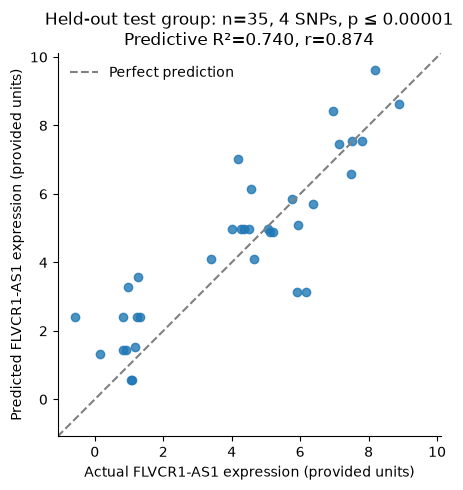

In [38]:
fig, ax = plt.subplots(figsize=(5.5, 5))
ax.scatter(test_y, test_prediction, alpha=0.8)
limits = [min(test_y.min(), test_prediction.min()) - 0.5, max(test_y.max(), test_prediction.max()) + 0.5]
ax.plot(limits, limits, linestyle='--', color='gray', label='Perfect prediction')
ax.set(xlim=limits, ylim=limits, aspect='equal', xlabel=f'Actual {gene_symbol} expression (provided units)',
    ylabel=f'Predicted {gene_symbol} expression (provided units)',
    title=f'Held-out test group: n={len(test_ids)}, {len(final_weights)} SNPs, p ≤ {best["Threshold"]:.5f}\nPredictive R²={test_predictive_r2:.3f}, r={test_r:.3f}')
ax.spines[['top', 'right']].set_visible(False)
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(gene_file('heldout_prediction.png'), dpi=180)
plt.show()

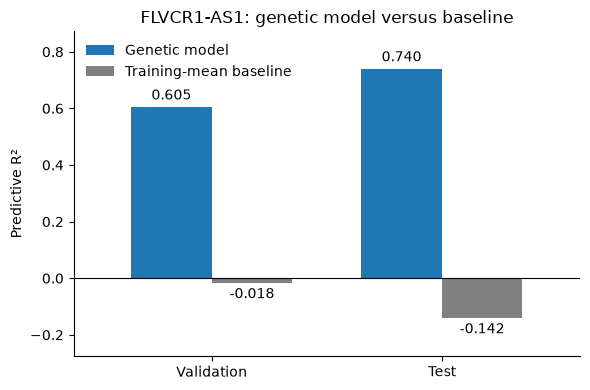

In [39]:
comparison = pd.DataFrame({'Genetic model': [best['Predictive_R2'], test_predictive_r2],
    'Training-mean baseline': [baseline_validation_r2, baseline_test_r2]}, index=['Validation', 'Test'])
fig, ax = plt.subplots(figsize=(6, 4))
comparison.plot.bar(ax=ax, color=['C0', 'gray'], rot=0, width=0.7)
for bars in ax.containers:
    ax.bar_label(bars, fmt='%.3f', padding=3)
ax.axhline(0, color='black', linewidth=0.8)
ax.margins(y=0.15)
ax.set(ylabel='Predictive R²', title=f'{gene_symbol}: genetic model versus baseline')
ax.spines[['top', 'right']].set_visible(False)
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(gene_file('model_vs_baseline.png'), dpi=180)
plt.show()

**Findings:** see Week 4 in [weekly_tasks_results.md](../weekly_tasks_results.md).

# Week 5 — 23andMe and Height Polygenic Risk Scores

Apply external height GWAS weights, clumped and with a fixed cutoff of **p ≤ 0.001**, across all 22 autosomes. The [assigned file](https://choishingwan.github.io/PRS-Tutorial/base/) comes from a tutorial that identifies its GWAS as **simulated**, so this is an educational comparison, not a validated estimate.

### Task 1: Tiffany's 23andMe Genotypes

The raw file is build 37 with plus-strand calls, matching our EUR reference panel, so no liftover is needed. We analyze autosomes only.

In [ ]:
from pathlib import Path
import subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm, gaussian_kde

w5 = Path('data/week5_results')
w5.mkdir(parents=True, exist_ok=True)
work5 = w5 / 'work'
work5.mkdir(exist_ok=True)
raw_files = list(Path('data').rglob('genome_Tiffany*.txt'))
if len(raw_files) != 1:
    raise FileNotFoundError('Locate exactly one original Tiffany 23andMe raw genotype file.')
raw_path = raw_files[0]
with raw_path.open() as handle:
    header = ''.join(next(handle) for _ in range(20))
assert 'build 37' in header and 'plus strand' in header
tiffany_raw = pd.read_csv(raw_path, sep='\t', comment='#', names=['SNP', 'CHR', 'BP', 'GT'],
                          dtype={'CHR': str, 'GT': str})
autosomal = tiffany_raw.CHR.isin([str(c) for c in range(1, 23)])
called_snp = tiffany_raw.GT.str.fullmatch('[ACGT]{2}')
conversion_input = tiffany_raw.loc[autosomal & called_snp].copy()
conversion_input['CHR'] = conversion_input.CHR.astype(int)
conversion_input.sort_values(['CHR', 'BP']).to_csv(w5 / 'Tiffany_autosomal_calls.tsv',
                                                 sep='\t', index=False, header=False)

### Converting 23andMe to VCF and PLINK

Following the [BCFtools tutorial](https://samtools.github.io/bcftools/howtos/convert.html), `convert --tsv2vcf` creates BCF, which PLINK2 imports. Only called diploid A/C/G/T SNPs are passed in, using the [public 1000 Genomes build 37 reference](https://www.internationalgenome.org/faq/which-reference-assembly-do-you-use/). No genotypes are sent to a service.

In [ ]:
reference_fasta = Path('data/reference/human_g1k_v37.autosomes.fa')
if not reference_fasta.is_file():
    raise FileNotFoundError('The build-37 autosomal reference FASTA is required for conversion.')
if not Path(str(reference_fasta) + '.fai').exists():
    subprocess.run(['samtools', 'faidx', str(reference_fasta)], check=True)
if not (w5 / 'Tiffany_autosomal.bcf').exists():
    converted = subprocess.run(['bcftools', 'convert', '--tsv2vcf', str(w5 / 'Tiffany_autosomal_calls.tsv'),
        '-f', str(reference_fasta), '-s', 'Tiffany', '-Ob', '-o', str(w5 / 'Tiffany_autosomal.bcf')],
        check=True, capture_output=True, text=True)
    (w5 / 'conversion_summary.txt').write_text(converted.stderr)
print((w5 / 'conversion_summary.txt').read_text())
if not (w5 / 'Tiffany_converted.bed').exists():
    subprocess.run([PLINK2, '--bcf', str(w5 / 'Tiffany_autosomal.bcf'), '--max-alleles', '2',
        '--snps-only', 'just-acgt', '--make-bed', '--threads', '2', '--memory', '1024',
        '--out', str(w5 / 'Tiffany_converted')], check=True, capture_output=True, text=True)
tiffany_bim = pd.read_csv(w5 / 'Tiffany_converted.bim', sep=r'\s+', header=None,
    names=['TCHR', 'SNP', 'CM', 'TBP', 'T1', 'T2'], keep_default_na=False)
display(pd.Series({'Original records': len(tiffany_raw), 'Outside autosomes': int((~autosomal).sum()),
    'Missing autosomal calls': int((autosomal & tiffany_raw.GT.eq('--')).sum()),
    'Other autosomal genotype codes': int((autosomal & ~called_snp & tiffany_raw.GT.ne('--')).sum()),
    'BCF input sites': len(conversion_input), 'PLINK sites retained': len(tiffany_bim)}).to_frame('Records'))

In [ ]:
import re
record_groups5 = pd.Series({'Converted autosomal SNPs': len(conversion_input), 'Outside autosomes': int((~autosomal).sum()),
    'Missing autosomal calls': int((autosomal & tiffany_raw.GT.eq('--')).sum()),
    'Other autosomal codes': int((autosomal & ~called_snp & tiffany_raw.GT.ne('--')).sum())})
assert record_groups5.sum() == len(tiffany_raw)
conversion_text5 = (w5 / 'conversion_summary.txt').read_text()
genotype_counts5 = pd.Series({name: int(re.search(rf'{code}:\s*(\d+)', conversion_text5).group(1))
    for name, code in [('Homozygous reference', 'Hom RR'), ('Heterozygous', 'Het RA'), ('Homozygous alternate', 'Hom AA')]})
fig, axes = plt.subplots(1, 2, figsize=(13, 3.4))
for ax, counts, title in [(axes[0], record_groups5, f"What happened to Tiffany's {len(tiffany_raw):,} records"),
                          (axes[1], genotype_counts5, f'Genotypes among {genotype_counts5.sum():,} converted SNPs')]:
    bars = ax.barh(counts.index, counts, color='C0')
    ax.bar_label(bars, labels=[f'{n:,} ({n / counts.sum():.1%})' for n in counts], padding=4)
    ax.invert_yaxis()
    ax.set_xlim(0, counts.max() * 1.35)
    ax.set_title(title)
    ax.xaxis.set_visible(False)
    ax.spines[['top', 'right', 'bottom']].set_visible(False)
fig.tight_layout()
fig.savefig(w5 / 'tiffany_genotype_summary.png', dpi=180)
plt.show()

### Exporting and Checking the VCF

BCFtools writes the VCF from the BCF, then we compare the same genotypes across the 23andMe calls, BCF, VCF, and PLINK. Allele order is ignored.

In [ ]:
import io, shutil
bcftools = shutil.which('bcftools')
vcf_path = w5 / 'Tiffany_autosomal.vcf.gz'
subprocess.run([bcftools, 'view', str(w5 / 'Tiffany_autosomal.bcf'), '-Oz', '-o', str(vcf_path)], check=True)

def read_calls(path):
    query = subprocess.run([bcftools, 'query', '-f', '%CHROM\t%POS\t%ID\t[%TGT]\n', str(path)],
        check=True, capture_output=True, text=True).stdout
    return pd.read_csv(io.StringIO(query), sep='\t', names=['CHR', 'BP', 'SNP', 'GT'], dtype=str, keep_default_na=False)

def unordered(genotypes):
    return genotypes.str.replace('/', '').map(lambda g: ''.join(sorted(g))).to_numpy()

bcf_calls, vcf_calls = read_calls(w5 / 'Tiffany_autosomal.bcf'), read_calls(vcf_path)
raw_calls = conversion_input.set_index('SNP').loc[vcf_calls['SNP']]
bed_codes = np.fromfile(w5 / 'Tiffany_converted.bed', dtype=np.uint8, offset=3) & 3  # one person: lowest 2 bits per SNP
t1, t2 = tiffany_bim['T1'].to_numpy(dtype=object), tiffany_bim['T2'].to_numpy(dtype=object)
plink_calls = pd.Series(np.select([bed_codes == 0, bed_codes == 2, bed_codes == 3], [t1 + t1, t1 + t2, t2 + t2], default='missing'),
                        index=tiffany_bim['SNP']).loc[vcf_calls['SNP']]
vcf_checks = {
    'VCF has the same sites and calls as BCF': vcf_calls.equals(bcf_calls),
    'VCF positions match the original 23andMe file': (raw_calls['BP'].astype(str).to_numpy() == vcf_calls['BP'].to_numpy()).all(),
    'VCF genotypes match the original 23andMe calls': (unordered(raw_calls['GT']) == unordered(vcf_calls['GT'])).all(),
    'PLINK genotypes match the VCF genotypes': (unordered(plink_calls.astype(str)) == unordered(vcf_calls['GT'])).all(),
    'All representations have the same sites': len(vcf_calls) == len(bcf_calls) == len(tiffany_bim) == len(conversion_input),
}
display(pd.Series(vcf_checks).to_frame('Passed'))
assert all(vcf_checks.values())

### Task 2: Height GWAS Summary Statistics

**A1 is the effect allele**, and the [tutorial](https://choishingwan.github.io/PRS-Tutorial/plink/) uses **BETA = ln(OR)**. Base QC follows the tutorial: **INFO > 0.8, MAF > 0.01**, valid alleles, unique SNP IDs, and no A/T or C/G SNPs.

In [ ]:
height_files = list(Path('data').rglob('Height.gwas.txt.gz'))
if len(height_files) != 1:
    raise FileNotFoundError('The assigned Height.gwas.txt.gz is required.')
height_gwas = pd.read_csv(height_files[0], sep='\t')
assert height_gwas.columns.tolist() == ['CHR', 'BP', 'SNP', 'A1', 'A2', 'N', 'SE', 'P', 'OR', 'INFO', 'MAF']
display(height_gwas.head(5))
assert height_gwas.OR.gt(0).all()
p_from_log_effect = 2 * norm.sf(abs(np.log(height_gwas.OR) / height_gwas.SE))
assert np.allclose(p_from_log_effect, height_gwas.P, rtol=0, atol=1e-5)
height_unique = height_gwas.drop_duplicates('SNP', keep='first').copy()
base_qc = (height_unique.INFO.gt(0.8) & height_unique.MAF.gt(0.01)
    & height_unique.P.between(0, 1) & height_unique.A1.isin(list('ACGT'))
    & height_unique.A2.isin(list('ACGT')) & height_unique.A1.ne(height_unique.A2)
    & ~(height_unique.A1 + height_unique.A2).isin(['AT', 'TA', 'CG', 'GC']))

In [ ]:
manhattan5 = height_unique[['CHR', 'BP', 'P']].sort_values(['CHR', 'BP'])
chromosome_offsets5 = manhattan5.groupby('CHR')['BP'].max().cumsum().shift(fill_value=0)
manhattan_x5 = (manhattan5['BP'] + manhattan5['CHR'].map(chromosome_offsets5)) / 1e6
fig, ax = plt.subplots(figsize=(13, 4))
ax.scatter(manhattan_x5, -np.log10(manhattan5['P']), s=3, c=np.where(manhattan5['CHR'] % 2, 'C0', 'gray'))
ax.axhline(-np.log10(0.001), linestyle='--', color='black', linewidth=1, label='Score cutoff, p = 0.001')
chromosome_middles5 = manhattan_x5.groupby(manhattan5['CHR']).median()
ax.set_xticks(chromosome_middles5, chromosome_middles5.index, fontsize=8)
ax.set(xlabel='Chromosome', ylabel='−log10(p)', title=f'Assigned height GWAS (simulated): {len(manhattan5):,} unique SNPs')
ax.margins(x=0.01)
ax.spines[['top', 'right']].set_visible(False)
ax.legend(frameon=False, loc='upper right')
fig.tight_layout()
fig.savefig(w5 / 'height_gwas_manhattan.png', dpi=180)
plt.show()

### Task 3: Clumping and Thresholding

Match GWAS SNPs to the EUR panel by ID, position, and alleles, then clump within 250 kb at **r² > 0.1** using EUR genotypes. Index SNPs with **p ≤ 0.001** are kept.

In [ ]:
reference_variants = pd.concat([pd.read_csv(f'data/LDREF/1000G.EUR.{c}.bim', sep=r'\s+', header=None,
    names=['CHR', 'SNP', 'CM', 'BP', 'R1', 'R2']) for c in range(1, 23)], ignore_index=True)
assert reference_variants.SNP.is_unique
reference_overlap = int(height_unique.SNP.isin(reference_variants.SNP).sum())
joined = height_unique.loc[base_qc].merge(reference_variants, on='SNP', suffixes=('_GWAS', ''))
complement5 = {'A': 'T', 'T': 'A', 'C': 'G', 'G': 'C'}
direct = ((joined.A1.eq(joined.R1) & joined.A2.eq(joined.R2))
          | (joined.A1.eq(joined.R2) & joined.A2.eq(joined.R1)))
c1, c2 = joined.A1.map(complement5), joined.A2.map(complement5)
reverse = ((c1.eq(joined.R1) & c2.eq(joined.R2)) | (c1.eq(joined.R2) & c2.eq(joined.R1)))
same_position = joined.CHR_GWAS.eq(joined.CHR) & joined.BP_GWAS.eq(joined.BP)
height_harmonized = joined.loc[(direct | reverse) & same_position].copy()
height_harmonized['A1'] = np.where(direct.loc[height_harmonized.index], height_harmonized.A1, c1.loc[height_harmonized.index])
height_harmonized['A2'] = np.where(direct.loc[height_harmonized.index], height_harmonized.A2, c2.loc[height_harmonized.index])
height_harmonized['BETA'] = np.log(height_harmonized.OR)
height_harmonized = height_harmonized[['CHR', 'BP', 'SNP', 'A1', 'A2', 'BETA', 'P', 'R1', 'R2']]
height_harmonized.to_csv(w5 / 'height_reference_harmonized.tsv.gz', sep='\t', index=False)

In [ ]:
height_indexes = []
for chrom in range(1, 23):
    table = height_harmonized.loc[height_harmonized.CHR.eq(chrom)]
    table.to_csv(work5 / 'chromosome_gwas.tsv', sep='\t', index=False)
    prefix = work5 / f'chr{chrom}'
    subprocess.run([PLINK2, '--bfile', f'data/LDREF/1000G.EUR.{chrom}',
        '--clump', str(work5 / 'chromosome_gwas.tsv'), '--clump-id-field', 'SNP', '--clump-p-field', 'P',
        '--clump-a1-field', 'A1', '--clump-p1', '1', '--clump-p2', '1', '--clump-r2', '0.1',
        '--clump-kb', '250', '--threads', '2', '--memory', '1024', '--out', str(prefix)],
        check=True, capture_output=True, text=True)
    height_indexes.extend(pd.read_csv(str(prefix) + '.clumps', sep=r'\s+')['ID'])
height_clumped = height_harmonized.loc[height_harmonized.SNP.isin(height_indexes)]
height_selected = height_clumped.loc[height_clumped.P.le(0.001)].copy()
height_selected.to_csv(w5 / 'height_clumped_p001.tsv', sep='\t', index=False)
print('Clump index SNPs:', len(height_clumped), '| Index SNPs with p ≤ 0.001:', len(height_selected))

### Task 4: Computing Height PRS

Keep selected SNPs with matching positions and alleles in Tiffany's calls and complete calls in all 489 reference people. A single-person BCF can omit the unobserved allele at a homozygous-reference site, so that label is filled in from the EUR variant pair; the call itself is unchanged. Everyone is scored on the same SNPs and weights.

In [ ]:
candidates5 = height_selected.merge(tiffany_bim, on='SNP')
candidates5 = candidates5.loc[candidates5.CHR.eq(candidates5.TCHR) & candidates5.BP.eq(candidates5.TBP)]
updates5, common_rows5 = [], []
for row in candidates5.itertuples(index=False):
    target = {row.R1, row.R2}
    observed = {a for a in [row.T1, row.T2] if a in complement5}
    if not observed: continue
    if observed <= target:
        flip = False
    elif {complement5[a] for a in observed} <= target:
        flip = True
    else:
        continue
    a1 = complement5.get(row.T1, '.') if flip else row.T1
    a2 = complement5.get(row.T2, '.') if flip else row.T2
    if a1 not in complement5: a1 = next(iter(target - {a2}))
    if a2 not in complement5: a2 = next(iter(target - {a1}))
    if {a1, a2} != target: continue
    updates5.append([row.SNP, row.T1, row.T2, a1, a2])
    common_rows5.append({**row._asdict(), 'Tiffany_complemented': flip})
height_common = pd.DataFrame(common_rows5)
reference_fam5 = pd.read_csv('data/LDREF/1000G.EUR.1.fam', sep=r'\s+', header=None, dtype=str)
observations5 = pd.concat([pd.read_csv(f'data/week2_results/chr{c}_frequency.afreq', sep='\t',
    usecols=['ID', 'OBS_CT']) for c in range(1, 23)]).set_index('ID')['OBS_CT']
height_common = height_common.loc[height_common.SNP.map(observations5).eq(2 * len(reference_fam5))]
height_common = height_common.sort_values('P').drop_duplicates(['CHR', 'BP']).sort_values(['CHR', 'BP'])
pd.DataFrame(updates5).loc[lambda x: x[0].isin(height_common.SNP)].to_csv(
    w5 / 'Tiffany_allele_updates.tsv', sep='\t', header=False, index=False)
height_common.SNP.to_csv(w5 / 'common_snps.txt', index=False, header=False)
height_common[['SNP', 'A1', 'BETA']].to_csv(w5 / 'height_common_weights.tsv', sep='\t', index=False)
height_common.to_csv(w5 / 'height_common_variants.tsv', sep='\t', index=False)

In [ ]:
subprocess.run([PLINK2, '--bfile', str(w5 / 'Tiffany_converted'),
    '--extract', str(w5 / 'common_snps.txt'), '--update-alleles', 'strict-missing',
    str(w5 / 'Tiffany_allele_updates.tsv'), '--make-bed', '--threads', '2', '--memory', '1024',
    '--out', str(w5 / 'Tiffany_common')], check=True, capture_output=True, text=True)
variant_stages5 = pd.DataFrame({'Stage': ['GWAS rows available', 'Unique GWAS SNPs',
    'SNP IDs overlapping EUR panel', 'Tutorial QC + allele/position harmonized',
    'LD-clumped index SNPs', 'Clumped SNPs meeting p ≤ 0.001',
    'SNPs at matching Tiffany positions', 'Shared harmonized complete-call scoring SNPs'],
    'SNPs': [len(height_gwas), len(height_unique), reference_overlap, len(height_harmonized),
             len(height_clumped), len(height_selected), len(candidates5), len(height_common)]})
display(variant_stages5)
variant_stages5.to_csv(w5 / 'variant_stages.tsv', sep='\t', index=False)
coverage5 = 100 * len(height_common) / len(height_selected)
print(f'Shared coverage: {coverage5:.2f}% of selected SNPs; lost {len(height_selected) - len(height_common):,}.')

In [ ]:
chromosomes5 = range(1, 23)
selected_by_chromosome5 = height_selected.groupby('CHR').size().reindex(chromosomes5, fill_value=0)
common_by_chromosome5 = height_common.groupby('CHR').size().reindex(chromosomes5, fill_value=0)
assert common_by_chromosome5.sum() == len(height_common)
fig, (stage_ax, chromosome_ax) = plt.subplots(1, 2, figsize=(14, 4.2), width_ratios=[1, 1.15])
bars = stage_ax.barh(variant_stages5['Stage'], variant_stages5['SNPs'], color='C0')
stage_ax.bar_label(bars, fmt='{:,.0f}', padding=4)
stage_ax.set_xscale('log')
stage_ax.set_xlim(1, variant_stages5['SNPs'].max() * 8)
stage_ax.invert_yaxis()
stage_ax.set_title('SNPs remaining at each stage (log scale)')
stage_ax.xaxis.set_visible(False)
stage_ax.spines['bottom'].set_visible(False)
positions5 = np.arange(len(chromosomes5))
chromosome_ax.bar(positions5 - 0.2, selected_by_chromosome5, width=0.4, color='gray', label='Selected, p ≤ 0.001')
chromosome_ax.bar(positions5 + 0.2, common_by_chromosome5, width=0.4, color='C0', label='Also usable in Tiffany')
chromosome_ax.set_xticks(positions5, chromosomes5, fontsize=9)
chromosome_ax.set(xlabel='Chromosome', ylabel='SNPs', title=f'Chip coverage by chromosome ({coverage5:.1f}% overall)')
chromosome_ax.legend(frameon=False)
for ax in (stage_ax, chromosome_ax):
    ax.spines[['top', 'right']].set_visible(False)
fig.tight_layout()
fig.savefig(w5 / 'snp_filtering_and_coverage.png', dpi=180)
plt.show()

The score is $PRS_i=\sum_j\beta_jG_{ij}$. We use PLINK2's **`BETA_SUM`**, summed across chromosomes, with `no-mean-imputation` so that missing calls are never filled in.

In [ ]:
reference_prs5 = pd.Series(0.0, index=reference_fam5[1], name='PRS')
chromosome_counts5 = []
for chrom in range(1, 23):
    fam = pd.read_csv(f'data/LDREF/1000G.EUR.{chrom}.fam', sep=r'\s+', header=None, dtype=str)
    assert fam[1].tolist() == reference_fam5[1].tolist()
    weights = height_common.loc[height_common.CHR.eq(chrom), ['SNP', 'A1', 'BETA']]
    weights.to_csv(work5 / 'chromosome_weights.tsv', sep='\t', index=False)
    prefix = work5 / f'score_chr{chrom}'
    if len(weights):
        subprocess.run([PLINK2, '--bfile', f'data/LDREF/1000G.EUR.{chrom}',
            '--score', str(work5 / 'chromosome_weights.tsv'), '1', '2', '3', 'header-read', 'no-mean-imputation',
            'cols=+scoresums', '--threads', '2', '--memory', '1024', '--out', str(prefix)],
            check=True, capture_output=True, text=True)
        scored = pd.read_csv(str(prefix) + '.sscore', sep=r'\s+', dtype={'IID': str}).set_index('IID')
        assert set(scored.index) == set(reference_prs5.index) and scored.ALLELE_CT.eq(2 * len(weights)).all()
        reference_prs5 = reference_prs5.add(scored.BETA_SUM)
    chromosome_counts5.append({'Chromosome': chrom, 'Scoring_SNPs': len(weights)})
subprocess.run([PLINK2, '--bfile', str(w5 / 'Tiffany_common'),
    '--score', str(w5 / 'height_common_weights.tsv'), '1', '2', '3', 'header-read', 'no-mean-imputation',
    'cols=+scoresums', '--threads', '2', '--memory', '1024', '--out', str(w5 / 'Tiffany_height')],
    check=True, capture_output=True, text=True)
tiffany_scored5 = pd.read_csv(w5 / 'Tiffany_height.sscore', sep=r'\s+')
assert tiffany_scored5.ALLELE_CT.eq(2 * len(height_common)).all()
tiffany_prs5 = float(tiffany_scored5.BETA_SUM.iloc[0])
reference_prs5.rename_axis('IID').to_csv(w5 / 'reference_height_prs.tsv', sep='\t')
pd.DataFrame(chromosome_counts5).to_csv(w5 / 'chromosome_scoring_counts.tsv', sep='\t', index=False)

### Comparing Tiffany With 1000 Genomes

The z-score uses the reference mean and sample SD. The percentile is a rank in this **489-person EUR reference**, with half-credit for ties. It is not a disease probability, and neither value converts to height.

In [ ]:
mean5, sd5 = reference_prs5.mean(), reference_prs5.std(ddof=1)
percentile5 = 100 * (reference_prs5.lt(tiffany_prs5).sum() + 0.5 * reference_prs5.eq(tiffany_prs5).sum()) / len(reference_prs5)
z5 = (tiffany_prs5 - mean5) / sd5
height_summary5 = pd.Series({'Reference individuals': len(reference_prs5), 'Shared scoring SNPs': len(height_common),
    'Reference mean': mean5, 'Reference median': reference_prs5.median(), 'Reference SD': sd5,
    'Reference minimum': reference_prs5.min(), 'Reference maximum': reference_prs5.max(),
    'Tiffany PRS': tiffany_prs5, 'Tiffany percentile': percentile5, 'Tiffany z-score': z5})
display(height_summary5.to_frame('Value'))
height_summary5.to_csv(w5 / 'height_prs_summary.tsv', sep='\t', header=['Value'])

### Independent Verification of the Scores

These checks do not rely on PLINK's scoring: effect alleles are counted from the original 23andMe calls and from the `.bed` bytes for all 489 reference people. PLINK's six-digit output can differ by a tiny rounding amount.

In [ ]:
final5 = height_common.merge(tiffany_raw, on='SNP', suffixes=('', '_raw'))
plus_strand_calls = [set(g) <= {a1, a2} for g, a1, a2 in zip(final5['GT'], final5['A1'], final5['A2'])]
tiffany_copies = np.array([g.count(a1) for g, a1 in zip(final5['GT'], final5['A1'])])
manual_tiffany = (final5['BETA'] * tiffany_copies).sum()

manual_reference = pd.Series(0.0, index=reference_fam5[1])
missing_reference_calls = 0
for chrom, snps in height_common.groupby('CHR'):
    panel = reference_variants.loc[reference_variants['CHR'].eq(chrom)].reset_index(drop=True)
    row = pd.Series(panel.index, index=panel['SNP'])
    bed = (Path(f'data/LDREF/1000G.EUR.{chrom}.bed')).read_bytes()
    bytes_per_snp = (len(manual_reference) + 3) // 4
    for snp, a1, beta in zip(snps['SNP'], snps['A1'], snps['BETA']):
        packed = np.frombuffer(bed, np.uint8, bytes_per_snp, 3 + row[snp] * bytes_per_snp)
        codes = np.stack([(packed >> shift) & 3 for shift in (0, 2, 4, 6)], axis=1).ravel()[:len(manual_reference)]
        missing_reference_calls += int((codes == 1).sum())
        copies_of_first_allele = np.select([codes == 0, codes == 2], [2, 1], default=0)  # .bim column 5
        copies = copies_of_first_allele if a1 == panel.loc[row[snp], 'R1'] else 2 - copies_of_first_allele
        manual_reference += beta * copies
display(pd.DataFrame({'Manual score': manual_reference, 'PLINK score': reference_prs5.loc[manual_reference.index]}).head(3))

tiffany_difference = abs(manual_tiffany - tiffany_prs5)
reference_difference = (manual_reference - reference_prs5.loc[manual_reference.index]).abs().max()
print(f'Maximum absolute difference, Tiffany: {tiffany_difference:.2e} | reference individuals: {reference_difference:.2e}')

gwas5 = height_gwas.drop_duplicates('SNP').set_index('SNP')
gwas_final = gwas5.loc[height_common['SNP']]
panel_final = reference_variants.set_index('SNP').loc[height_common['SNP']]
selected_gwas_p = gwas5.loc[height_selected['SNP'], 'P'].to_numpy()
clump_logs = [(work5 / f'chr{c}.log').read_text() for c in range(1, 23)]
manual_mean, manual_sd = manual_reference.mean(), manual_reference.std(ddof=1)
below5, above5 = int((manual_reference < manual_tiffany).sum()), int((manual_reference > manual_tiffany).sum())
recalculated5 = {'Tiffany PRS': manual_tiffany, 'Reference mean': manual_mean, 'Reference SD': manual_sd,
    'Tiffany percentile': 100 * below5 / len(manual_reference), 'Tiffany z-score': (manual_tiffany - manual_mean) / manual_sd,
    'Reference individuals below Tiffany': below5, 'Reference individuals above Tiffany': above5}
display(pd.Series(recalculated5).to_frame('Recalculated value'))

score_checks = {
    '23andMe header states build 37 and plus strand': 'build 37' in header and 'plus strand' in header,
    'GWAS, reference, and Tiffany coordinates agree': (gwas_final['BP'].to_numpy() == final5['BP'].to_numpy()).all()
        and (panel_final['BP'].to_numpy() == final5['BP'].to_numpy()).all() and (final5['BP_raw'].to_numpy() == final5['BP'].to_numpy()).all(),
    'Effect alleles match the GWAS and reference alleles': (gwas_final['A1'].to_numpy() == final5['A1'].to_numpy()).all()
        and all({a, b} == {r1, r2} for a, b, r1, r2 in zip(final5['A1'], final5['A2'], final5['R1'], final5['R2'])),
    'No strand-ambiguous scoring SNPs': not (final5['A1'] + final5['A2']).isin(['AT', 'TA', 'CG', 'GC']).any(),
    'Tiffany calls need no complementing': all(plus_strand_calls) and not final5['Tiffany_complemented'].any(),
    'No missing genotypes to impute': final5['GT'].str.fullmatch('[ACGT]{2}').all() and missing_reference_calls == 0,
    'Everyone scored on the same unique SNPs': len(final5) == height_common['SNP'].nunique(),
    'Weights equal ln(OR) from the GWAS': np.allclose(final5['BETA'], np.log(gwas_final['OR'])),
    'All 22 autosomes contribute': sorted(final5['CHR'].unique()) == list(range(1, 23)),
    'All 489 reference people scored': len(manual_reference) == len(reference_prs5) == 489,
    'Fixed threshold: 10 × 10^-4 = 0.001': np.isclose(10 * 10**-4, 0.001),
    'Selected SNPs use their GWAS p-values, p ≤ 0.001': (height_selected['P'].to_numpy() == selected_gwas_p).all() and (selected_gwas_p <= 0.001).all(),
    '8,700 SNPs selected across 22 autosomes': len(height_selected) == 8700 and height_selected['CHR'].nunique() == 22,
    'All 22 clumping runs used r² = 0.1 and 250 kb': all('--clump-r2 0.1' in log and '--clump-kb 250' in log for log in clump_logs),
    'Tiffany manual score matches PLINK': tiffany_difference < 1e-5,
    'Reference manual scores match PLINK': reference_difference < 1e-5,
}
display(pd.Series(score_checks).to_frame('Passed'))
assert all(score_checks.values())

### Height PRS Distribution

Reference scores with a kernel density estimate, and Tiffany's score on the same scale.

In [ ]:
fig5, ax5 = plt.subplots(figsize=(10, 5.5))
ax5.hist(reference_prs5, bins=24, density=True, alpha=0.5, color='steelblue', edgecolor='white',
         label=f'1000 Genomes EUR (n={len(reference_prs5)})')
x5 = np.linspace(min(reference_prs5.min(), tiffany_prs5) - 0.3 * sd5,
                 max(reference_prs5.max(), tiffany_prs5) + 0.3 * sd5, 400)
ax5.plot(x5, gaussian_kde(reference_prs5)(x5), color='steelblue', label='Empirical KDE')
ax5.axvline(tiffany_prs5, color='crimson', linewidth=2.2, label=f'Tiffany PRS = {tiffany_prs5:.5f}')
ax5.axvline(mean5, color='black', linestyle='--', label=f'Reference mean = {mean5:.5f}')
ax5.set(xlabel='Height polygenic score (PRS)', ylabel='Density',
        title='Height PRS Distribution: 1000 Genomes Reference and Tiffany')
ax5.text(0.02, 0.97, f'Tiffany: percentile {percentile5:.2f}\nz-score {z5:.3f}\n{len(height_common):,} shared SNPs; p ≤ 0.001',
         transform=ax5.transAxes, va='top', bbox={'facecolor': 'white', 'alpha': 0.9, 'edgecolor': 'none'})
ax5.legend(loc='upper right', fontsize=9)
fig5.tight_layout(rect=(0, 0.06, 1, 1))
fig5.text(0.5, 0.025, 'Educational comparison using simulated-height GWAS weights; scores are not height in cm.',
          ha='center', fontsize=9)
height_figure5 = w5 / 'week5_height_prs_distribution.png'
fig5.savefig(height_figure5, dpi=300)
plt.show()

**Findings:** see Week 5 in [weekly_tasks_results.md](../weekly_tasks_results.md). Personal results stay local in `data/week5_results/week5_personal_results.md`.

# Week 6 — LocusZoom and Linkage Disequilibrium

A **LocusZoom plot** shows one genomic region: each point is a SNP, placed by position and −log10(p) and colored by its LD with the **lead SNP**, the one with the smallest p-value.

Week 4 only mapped chromosome 1, so we repeat its method on chromosome 22.

### Step 1: Map Chromosome 22

In [56]:
from pathlib import Path
import gzip
import json
import os
import subprocess
import sys
import urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import linregress, t as t_distribution
from IPython.display import Image, display
from src.eqtl import fit_cis
from src.locuszoom import gene_track, write_locuszoom_page

w6 = Path('data/week6_results')
w6.mkdir(parents=True, exist_ok=True)
w6_prefix = 'data/LDREF/1000G.EUR.22'
w6_keep = Path('data/week4_results/matched.keep')
w6_samples = pd.read_csv('data/week2_results/matched_sample_ids.tsv', sep='\t', dtype=str)
w6_ids = w6_samples['IID'].tolist()
w6_column = dict(zip(w6_ids, w6_samples['FID'] + '_' + w6_samples['IID']))
assert pd.read_csv(w6_keep, sep='\t', header=None, dtype=str)[1].tolist() == w6_ids

w6_gtf = w6 / 'chr22.gencode12.GRCh37.gtf'
if not w6_gtf.exists():
    gencode_url = 'https://ftp.ebi.ac.uk/pub/databases/gencode/Gencode_human/release_12/gencode.v12.annotation.gtf.gz'
    with urllib.request.urlopen(gencode_url) as download, gzip.open(download, 'rt') as source, w6_gtf.open('w') as output:
        output.write(f'# Source: {gencode_url}\n# GRCh37; GENCODE v12; chromosome 22 gene and exon records only; 1-based inclusive\n')
        output.writelines(line for line in source if line.startswith('chr22\t') and line.split('\t', 3)[2] in ('gene', 'exon'))

expression_chunks = pd.read_csv('data/GD462.GeneQuantRPKM.50FN.samplename.resk10.txt',
    sep='\t', usecols=['TargetID', 'Chr', 'Coord', *w6_ids], dtype={'Chr': str}, chunksize=2000)
w6_expression = pd.concat([c.loc[c['Chr'].eq('22')] for c in expression_chunks]).set_index('TargetID')
fam_ids = pd.read_csv(f'{w6_prefix}.fam', sep=r'\s+', header=None, dtype=str)[1]
assert set(w6_ids) <= set(fam_ids) and w6_samples['IID'].is_unique
print('Matched individuals:', len(w6_ids), '| Expressed chromosome 22 genes:', len(w6_expression))

Matched individuals: 344 | Expressed chromosome 22 genes: 633


In [57]:
gtf6 = pd.read_csv(w6_gtf, sep='\t', comment='#', header=None)
gene_rows6 = gtf6.loc[gtf6[2].eq('gene')]
w6_annotation = pd.DataFrame({
    'Gene_ID': gene_rows6[8].str.extract(r'gene_id "([^"]+)"')[0],
    'Symbol': gene_rows6[8].str.extract(r'gene_name "([^"]+)"')[0],
    'Gene_type': gene_rows6[8].str.extract(r'gene_type "([^"]+)"')[0],
    'Start': gene_rows6[3], 'End': gene_rows6[4], 'Strand': gene_rows6[6],
}).set_index('Gene_ID')
w6_genes = w6_annotation.reindex(w6_expression.index).copy()
w6_genes['Cis_start'] = (w6_genes['Start'] - 500000).clip(lower=1)
w6_genes['Cis_end'] = w6_genes['End'] + 500000
y_values6 = w6_expression[w6_ids].to_numpy(float)
w6_genes['Reason'] = 'Eligible'
w6_genes.loc[w6_genes['Start'].isna(), 'Reason'] = 'No exact-version GRCh37 annotation'
outside6 = ~w6_expression['Coord'].between(w6_genes['Start'], w6_genes['End'])
w6_genes.loc[outside6 & w6_genes['Start'].notna(), 'Reason'] = 'Expression coordinate outside gene body'
w6_genes.loc[np.isfinite(y_values6).sum(axis=1) < 3, 'Reason'] = 'Fewer than 3 expression observations'
w6_genes.loc[np.nanstd(y_values6, axis=1) == 0, 'Reason'] = 'Constant expression'

In [58]:
if not (w6 / 'chr22_matched.traw').exists():
    subprocess.run([PLINK2, '--bfile', w6_prefix, '--keep', str(w6_keep),
        '--snps-only', 'just-acgt', '--min-alleles', '2', '--max-alleles', '2',
        '--export', 'Av', '--threads', '2', '--memory', '1024', '--out', str(w6 / 'chr22_matched')],
        check=True, capture_output=True, text=True)
w6_variants = pd.read_csv(w6 / 'chr22_matched.traw', sep=r'\s+')
assert w6_variants['CHR'].eq(22).all() and set(w6_column.values()) <= set(w6_variants.columns)

association_path6 = w6 / 'chr22_cis_eqtl.tsv.gz'
if not association_path6.exists():
    chr22_tables = []
    for gene, region in w6_genes.loc[w6_genes['Reason'].eq('Eligible')].iterrows():
        nearby = w6_variants.loc[w6_variants['POS'].between(region.Cis_start, region.Cis_end)]
        result = fit_cis(nearby, w6_ids, w6_expression.loc[gene, w6_ids], w6_column) if len(nearby) else nearby
        if len(result):
            chr22_tables.append(result.assign(Gene_ID=gene))
    pd.concat(chr22_tables, ignore_index=True).to_csv(association_path6, sep='\t', index=False, compression='gzip')
w6_associations = pd.read_csv(association_path6, sep='\t')
assert w6_associations['CHR'].eq(22).all() and w6_associations['P'].notna().all()
print('Finished chromosome 22 mapping:', f'{len(w6_associations):,} regressions')

Finished chromosome 22 mapping: 280,657 regressions


### Step 2: Count Significant cis-eQTLs on Chromosome 22

A pair is significant at p < 0.05 / (chromosome 22 SNP–gene tests). One SNP can count for several genes.

In [59]:
w6_tests = len(w6_associations)
w6_cutoff = 0.05 / w6_tests
w6_associations['Significant'] = w6_associations['P'].lt(w6_cutoff)
significant6 = w6_associations.loc[w6_associations['Significant']]
w6_gene_summary = (w6_associations.groupby('Gene_ID')
    .agg(SNPs_tested=('SNP', 'size'), Min_p=('P', 'min'), Significant_SNPs=('Significant', 'sum'))
    .join(w6_genes[['Symbol', 'Gene_type', 'Start', 'End', 'Cis_start', 'Cis_end']]).sort_values('Min_p'))
no_snps6 = w6_genes['Reason'].eq('Eligible') & ~w6_genes.index.isin(w6_gene_summary.index)
w6_genes.loc[no_snps6, 'Reason'] = 'No eligible cis-SNPs'
w6_gene_summary.to_csv(w6 / 'chr22_gene_summary.tsv', sep='\t')
display(w6_genes['Reason'].value_counts().to_frame('Genes'))
print(f'Total chromosome 22 SNP–gene tests: {w6_tests:,}')
print(f'Bonferroni p-value cutoff: 0.05 / {w6_tests:,} = {w6_cutoff:.4e}')
print(f'Significant SNP–gene associations: {len(significant6):,}')
print(f'Unique genes with a significant association: {significant6["Gene_ID"].nunique()} of {len(w6_gene_summary)} analyzed')
print(f'Unique significant SNP IDs (not the required count): {significant6["SNP"].nunique():,}')

,Genes
Reason,
Eligible,633


Total chromosome 22 SNP–gene tests: 280,657
Bonferroni p-value cutoff: 0.05 / 280,657 = 1.7815e-07
Significant SNP–gene associations: 1,316
Unique genes with a significant association: 72 of 633 analyzed
Unique significant SNP IDs (not the required count): 957


### Step 3: Select One Gene Locus

Among genes with **at least 10 Bonferroni-significant SNPs**, take the one with the **smallest p-value**. This uses association results only, not LD counts.

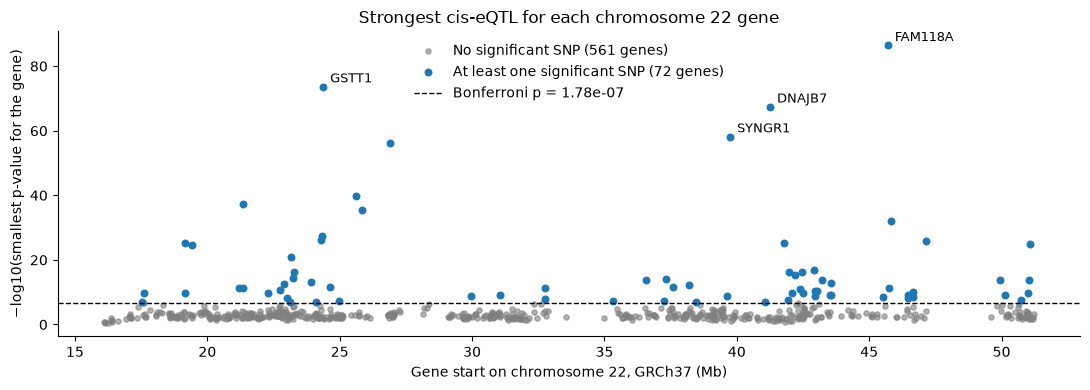

In [60]:
fig, ax = plt.subplots(figsize=(11, 4))
hit6 = w6_gene_summary['Significant_SNPs'].gt(0)
ax.scatter(w6_gene_summary.loc[~hit6, 'Start'] / 1e6, -np.log10(w6_gene_summary.loc[~hit6, 'Min_p']), s=14, color='gray', alpha=0.6,
           label=f'No significant SNP ({(~hit6).sum()} genes)')
ax.scatter(w6_gene_summary.loc[hit6, 'Start'] / 1e6, -np.log10(w6_gene_summary.loc[hit6, 'Min_p']), s=22, color='C0',
           label=f'At least one significant SNP ({hit6.sum()} genes)')
ax.axhline(-np.log10(w6_cutoff), linestyle='--', color='black', linewidth=1, label=f'Bonferroni p = {w6_cutoff:.2e}')
for gene in w6_gene_summary.head(4).itertuples():
    ax.annotate(gene.Symbol, (gene.Start / 1e6, -np.log10(gene.Min_p)), xytext=(5, 3), textcoords='offset points', fontsize=9)
ax.set(xlabel='Gene start on chromosome 22, GRCh37 (Mb)', ylabel='−log10(smallest p-value for the gene)',
       title='Strongest cis-eQTL for each chromosome 22 gene')
ax.spines[['top', 'right']].set_visible(False)
ax.legend(frameon=False, loc='upper center')
fig.tight_layout()
fig.savefig(w6 / 'chr22_gene_summary.png', dpi=180)
plt.show()

In [61]:
candidates6 = w6_gene_summary.loc[w6_gene_summary['Significant_SNPs'].ge(10)]
display(candidates6.head(8)[['Symbol', 'Gene_type', 'SNPs_tested', 'Significant_SNPs', 'Min_p']])
w6_gene_id = candidates6.index[0]
w6_gene = w6_gene_summary.loc[w6_gene_id]
w6_symbol = w6_gene['Symbol']
w6_start, w6_end = int(w6_gene['Cis_start']), int(w6_gene['Cis_end'])
w6_locus = (w6_associations.loc[w6_associations['Gene_ID'].eq(w6_gene_id)]
    .sort_values(['P', 'POS', 'SNP']).reset_index(drop=True))
w6_lead = w6_locus.iloc[0]
assert w6_locus['POS'].is_unique and w6_locus['SNP'].is_unique
exact_ties6 = int(w6_locus['P'].eq(w6_lead['P']).sum())
print(f'Gene: {w6_symbol} ({w6_gene_id}), {w6_gene["Gene_type"]}')
print(f'Gene body: chr22:{int(w6_gene["Start"]):,}–{int(w6_gene["End"]):,}')
print(f'Cis-window: chr22:{w6_start:,}–{w6_end:,}')
print(f'SNPs tested: {len(w6_locus)} | Bonferroni-significant: {int(w6_locus["Significant"].sum())}')
print(f'Lead SNP: {w6_lead["SNP"]} at chr22:{w6_lead["POS"]:,}')
print(f'Lead p-value: {w6_lead["P"]:.4e} | −log10(p): {-np.log10(w6_lead["P"]):.3f} | SNPs with exactly this p: {exact_ties6}')
display(w6_locus.head(7)[['SNP', 'POS', 'COUNTED', 'BETA', 'SE', 'P']])

,Symbol,Gene_type,SNPs_tested,Significant_SNPs,Min_p
Gene_ID,,,,,
ENSG00000100376.7,FAM118A,protein_coding,636,28,3.256798e-87
ENSG00000184674.7,GSTT1,protein_coding,392,49,2.032860e-74
ENSG00000172404.4,DNAJB7,protein_coding,292,89,3.611015e-68
ENSG00000100321.10,SYNGR1,protein_coding,397,30,6.332549e-59
ENSG00000260065.1,CTA-445C9.15,lincRNA,790,48,4.482008e-57
ENSG00000244752.2,CRYBB2,protein_coding,464,22,2.054450e-40
ENSG00000230513.1,THAP7-AS1,antisense,371,12,5.614230e-38
ENSG00000100058.7,CRYBB2P1,pseudogene,581,19,2.579154e-36


Gene: FAM118A (ENSG00000100376.7), protein_coding
Gene body: chr22:45,704,849–45,737,836
Cis-window: chr22:45,204,849–46,237,836
SNPs tested: 636 | Bonferroni-significant: 28
Lead SNP: rs104664 at chr22:45,711,854
Lead p-value: 3.2568e-87 | −log10(p): 86.487 | SNPs with exactly this p: 1


,SNP,POS,COUNTED,BETA,SE,P
0,rs104664,45711854,A,-13.171090,0.485757,3.256798e-87
1,rs3827393,45736153,A,-13.337077,0.496923,3.509309e-86
2,rs6006992,45742760,G,-13.337077,0.496923,3.509309e-86
3,rs1569413,45756081,A,-13.337077,0.496923,3.509309e-86
4,rs136564,45764874,T,-13.337077,0.496923,3.509309e-86
5,rs470062,45767369,A,-13.337077,0.496923,3.509309e-86
6,rs3747240,45740224,A,-13.197947,0.502943,6.320358e-84


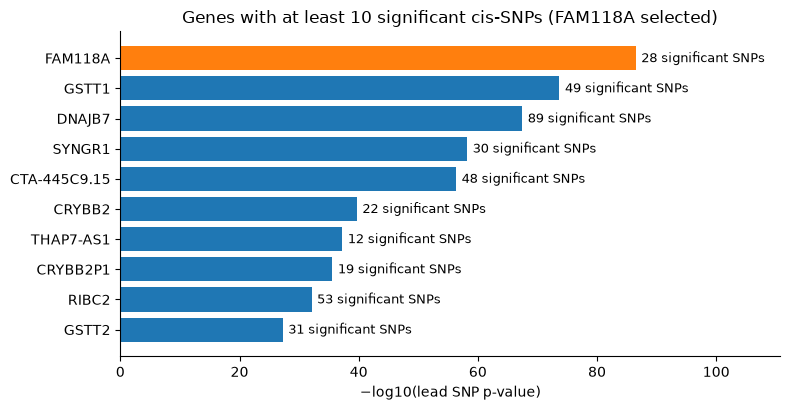

In [62]:
top6 = candidates6.head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 4.2))
bars = ax.barh(top6['Symbol'], -np.log10(top6['Min_p']), color=['C1' if g == w6_gene_id else 'C0' for g in top6.index])
ax.bar_label(bars, labels=[f'{n} significant SNPs' for n in top6['Significant_SNPs']], padding=4, fontsize=9)
ax.set_xlim(0, (-np.log10(top6['Min_p'])).max() * 1.28)
ax.set(xlabel='−log10(lead SNP p-value)', title=f'Genes with at least 10 significant cis-SNPs ({w6_symbol} selected)')
ax.spines[['top', 'right']].set_visible(False)
fig.tight_layout()
fig.savefig(w6 / 'gene_selection.png', dpi=180)
plt.show()

### Step 4: Prepare the Summary Statistics

Keep all tested SNPs in the cis-window, not only the significant ones. −log10(p) is calculated once here, and LocusZoom receives it as is.

In [63]:
w6_sumstats = pd.DataFrame({
    'SNP': w6_locus['SNP'], 'CHR': w6_locus['CHR'], 'Position': w6_locus['POS'], 'Counted_Allele': w6_locus['COUNTED'],
    'BETA': w6_locus['BETA'], 'SE': w6_locus['SE'], 'N': w6_locus['N'], 'P': w6_locus['P'],
    'Minus_Log10_P': -np.log10(w6_locus['P']), 'Significant': w6_locus['Significant'],
    'Lead_SNP': w6_locus['SNP'].eq(w6_lead['SNP']),
}).sort_values('Position').reset_index(drop=True)
assert w6_sumstats['Lead_SNP'].sum() == 1 and np.isclose(10.0 ** -w6_sumstats['Minus_Log10_P'], w6_sumstats['P'], rtol=1e-10).all()
sumstats_path6 = w6 / f'{w6_symbol}_summary_statistics.tsv'
w6_sumstats.to_csv(sumstats_path6, sep='\t', index=False)
print('Saved', sumstats_path6, w6_sumstats.shape)
display(w6_sumstats.head(3))

Saved data/week6_results/FAM118A_summary_statistics.tsv (636, 11)


,SNP,CHR,Position,Counted_Allele,BETA,SE,N,P,Minus_Log10_P,Significant,Lead_SNP
0,rs6007305,22,45205728,A,-0.254274,0.586739,344,0.665020,0.177165,False,False
1,rs16991944,22,45207319,G,-1.850382,1.265687,344,0.144671,0.839619,False,False
2,rs9626568,22,45207597,T,0.011076,0.602462,344,0.985343,0.006413,False,False


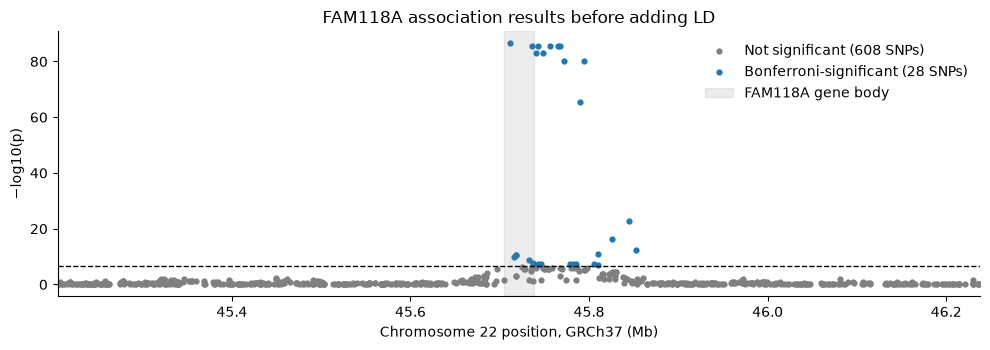

In [64]:
fig, ax = plt.subplots(figsize=(10, 3.6))
for significant, color, label in [(False, 'gray', 'Not significant'), (True, 'C0', 'Bonferroni-significant')]:
    rows = w6_sumstats.loc[w6_sumstats['Significant'].eq(significant)]
    ax.scatter(rows['Position'] / 1e6, rows['Minus_Log10_P'], s=12, color=color, label=f'{label} ({len(rows)} SNPs)')
ax.axvspan(w6_gene['Start'] / 1e6, w6_gene['End'] / 1e6, color='gray', alpha=0.15, label=f'{w6_symbol} gene body')
ax.axhline(-np.log10(w6_cutoff), linestyle='--', color='black', linewidth=1)
ax.set(xlim=(w6_start / 1e6, w6_end / 1e6), xlabel='Chromosome 22 position, GRCh37 (Mb)', ylabel='−log10(p)',
       title=f'{w6_symbol} association results before adding LD')
ax.spines[['top', 'right']].set_visible(False)
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(w6 / f'{w6_symbol}_association_only.png', dpi=180)
plt.show()

### Step 5: Calculate LD With PLINK2

`--r2-unphased` gives the squared correlation of genotype dosages in the same 344 people. `--ld-window-kb` and `--ld-window-r2 0` override PLINK's defaults, so distant and low-LD pairs are kept. The table accounts for every SNP.

In [65]:
ld_prefix6 = w6 / f'{w6_symbol}_lead_ld'
ld_command6 = [PLINK2, '--bfile', w6_prefix, '--keep', str(w6_keep),
    '--chr', '22', '--from-bp', str(w6_start), '--to-bp', str(w6_end),
    '--snps-only', 'just-acgt', '--min-alleles', '2', '--max-alleles', '2',
    '--r2-unphased', 'cols=+freq', '--ld-snp', w6_lead['SNP'],
    '--ld-window-kb', '100000', '--ld-window-r2', '0',
    '--threads', '2', '--memory', '1024', '--out', str(ld_prefix6)]
subprocess.run(ld_command6, check=True, capture_output=True, text=True)
ld_pairs6 = pd.read_csv(f'{ld_prefix6}.vcor', sep='\t', na_values=['nan', 'NA'])
assert ld_pairs6['ID_A'].eq(w6_lead['SNP']).all() and ld_pairs6['ID_B'].is_unique

bim6 = pd.read_csv(f'{w6_prefix}.bim', sep=r'\s+', header=None, names=['CHR', 'SNP', 'CM', 'POS', 'A1', 'A2'])
window_snps6 = bim6.loc[bim6['POS'].between(w6_start, w6_end), 'SNP']
untested6 = sorted(set(window_snps6) - set(w6_locus['SNP']))
no_ld6 = sorted(set(w6_locus['SNP']) - {w6_lead['SNP']} - set(ld_pairs6.loc[ld_pairs6['UNPHASED_R2'].notna(), 'ID_B']))
extra_pairs6 = sorted(set(ld_pairs6['ID_B']) - set(w6_locus['SNP']))
ld_accounting6 = pd.Series({
    'Reference SNPs in the cis-window': len(window_snps6),
    'Tested SNPs (variable, A/C/G/T, biallelic)': len(w6_locus),
    'Untested reference SNPs': len(untested6),
    'PLINK pairs with the lead SNP': len(ld_pairs6),
    'Pairs PLINK reported as nan': int(ld_pairs6['UNPHASED_R2'].isna().sum()),
    'Tested non-lead SNPs without a valid r²': len(no_ld6),
    'PLINK pairs beyond the tested SNPs': len(extra_pairs6),
    'Missing genotype calls in the window': int(w6_variants.loc[w6_variants['SNP'].isin(window_snps6), list(w6_column.values())].isna().sum().sum()),
})
display(ld_accounting6.to_frame('Count'))

,Count
Reference SNPs in the cis-window,636
"Tested SNPs (variable, A/C/G/T, biallelic)",636
Untested reference SNPs,0
PLINK pairs with the lead SNP,635
Pairs PLINK reported as nan,0
Tested non-lead SNPs without a valid r²,0
PLINK pairs beyond the tested SNPs,0
Missing genotype calls in the window,0


A NumPy recalculation from the exported dosages checks PLINK's r² for every SNP.

In [66]:
ld_lookup6 = ld_pairs6.set_index('ID_B')['UNPHASED_R2']
w6_ld_table = w6_sumstats[['SNP', 'Position', 'P', 'Minus_Log10_P', 'Lead_SNP', 'Significant']].copy()
w6_ld_table.insert(4, 'LD_R2', w6_ld_table['SNP'].map(ld_lookup6))
w6_ld_table.loc[w6_ld_table['Lead_SNP'], 'LD_R2'] = 1.0
assert w6_ld_table['LD_R2'].notna().all()
ld_table_path6 = w6 / f'{w6_symbol}_ld_table.tsv'
w6_ld_table.to_csv(ld_table_path6, sep='\t', index=False)
print('Saved', ld_table_path6, w6_ld_table.shape)

dosages6 = w6_variants.set_index('SNP').loc[w6_ld_table['SNP'], list(w6_column.values())].to_numpy(float)
lead_dosage6 = dosages6[w6_ld_table['Lead_SNP'].to_numpy()][0]
w6_ld_table['Manual_R2'] = [np.corrcoef(lead_dosage6, row)[0, 1] ** 2 for row in dosages6]
biggest_difference6 = (w6_ld_table['LD_R2'] - w6_ld_table['Manual_R2']).abs().max()
assert biggest_difference6 < 1e-4
assert np.isclose(w6_ld_table.loc[w6_ld_table['Lead_SNP'], 'Manual_R2'], 1).all()
print(f'Largest |PLINK r² − manual r²| across {len(w6_ld_table)} SNPs: {biggest_difference6:.2e}')

Saved data/week6_results/FAM118A_ld_table.tsv (636, 7)
Largest |PLINK r² − manual r²| across 636 SNPs: 4.97e-07


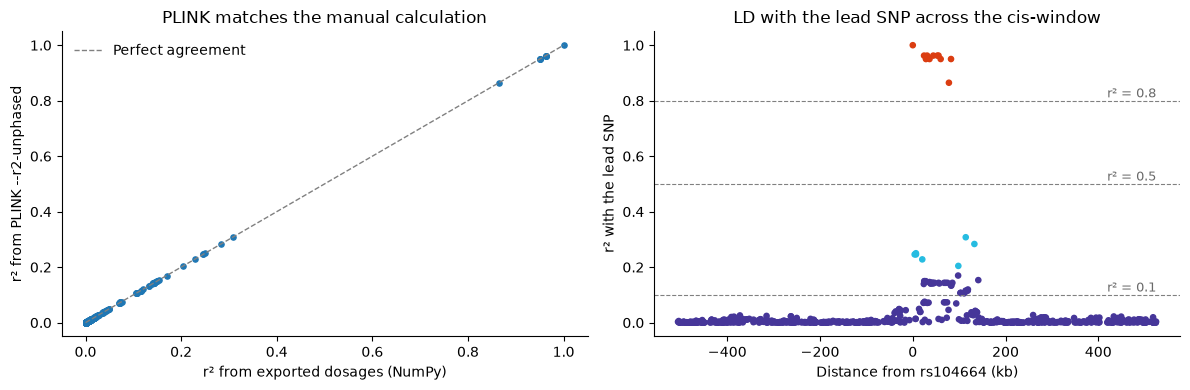

In [67]:
ld_breaks6 = [0, 0.2, 0.4, 0.6, 0.8, 1.0000001]
ld_rgb6 = np.array([(70, 54, 153), (38, 188, 225), (110, 254, 104), (248, 195, 42), (219, 61, 17)])
ld_bin6 = np.digitize(w6_ld_table['LD_R2'], ld_breaks6) - 1
distance6 = (w6_ld_table['Position'] - w6_lead['POS']) / 1e3
fig, (check_ax, decay_ax) = plt.subplots(1, 2, figsize=(12, 4))
check_ax.scatter(w6_ld_table['Manual_R2'], w6_ld_table['LD_R2'], s=14, color='C0')
check_ax.plot([0, 1], [0, 1], linestyle='--', color='gray', linewidth=1, label='Perfect agreement')
check_ax.set(xlabel='r² from exported dosages (NumPy)', ylabel='r² from PLINK --r2-unphased', title='PLINK matches the manual calculation')
check_ax.legend(frameon=False)
decay_ax.scatter(distance6, w6_ld_table['LD_R2'], s=14, c=ld_rgb6[ld_bin6] / 255)
for threshold in [0.8, 0.5, 0.1]:
    decay_ax.axhline(threshold, linestyle='--', color='gray', linewidth=0.8)
    decay_ax.text(distance6.max(), threshold + 0.012, f'r² = {threshold}', ha='right', fontsize=9, color='dimgray')
decay_ax.set(xlabel=f'Distance from {w6_lead["SNP"]} (kb)', ylabel='r² with the lead SNP', title='LD with the lead SNP across the cis-window')
for ax in (check_ax, decay_ax):
    ax.spines[['top', 'right']].set_visible(False)
fig.tight_layout()
fig.savefig(w6 / f'{w6_symbol}_ld_checks.png', dpi=180)
plt.show()

### Step 6: Count SNPs in LD With the Lead SNP

Counts cover tested non-lead SNPs with strict `>`, for all SNPs and for Bonferroni-significant ones.

In [68]:
others6 = w6_ld_table.loc[~w6_ld_table['Lead_SNP']]
w6_thresholds = [0.8, 0.5, 0.1]
w6_counts = pd.DataFrame({
    'All tested SNPs': [int(others6['LD_R2'].gt(t).sum()) for t in w6_thresholds],
    'Bonferroni-significant SNPs': [int((others6['LD_R2'].gt(t) & others6['Significant']).sum()) for t in w6_thresholds],
}, index=[f'r² > {t}' for t in w6_thresholds])
assert w6_counts.apply(lambda c: c.is_monotonic_increasing).all()
w6_counts.to_csv(w6 / f'{w6_symbol}_ld_counts.tsv', sep='\t')
print(f'Gene: {w6_symbol} | Lead SNP: {w6_lead["SNP"]} (excluded from counts; self-LD r² = 1)')
print(f'Non-lead SNPs with valid LD: {len(others6)} | Non-lead significant SNPs: {int(others6["Significant"].sum())}')
display(w6_counts)
low_ld_hits6 = others6.loc[others6['Significant'] & others6['LD_R2'].le(0.1)].sort_values('P')
print(f'Significant SNPs with r² ≤ 0.1: {len(low_ld_hits6)}')
display(low_ld_hits6[['SNP', 'Position', 'P', 'LD_R2']])
print('SNPs with r² between 0.5 and 0.8:', int(others6['LD_R2'].between(0.5, 0.8).sum()),
      '| Largest r² at or below 0.8:', round(others6.loc[others6['LD_R2'].le(0.8), 'LD_R2'].max(), 4),
      '| Smallest r² above 0.8:', round(others6.loc[others6['LD_R2'].gt(0.8), 'LD_R2'].min(), 4))

Gene: FAM118A | Lead SNP: rs104664 (excluded from counts; self-LD r² = 1)
Non-lead SNPs with valid LD: 635 | Non-lead significant SNPs: 27


,All tested SNPs,Bonferroni-significant SNPs
r² > 0.8,10,10
r² > 0.5,10,10
r² > 0.1,48,19


Significant SNPs with r² ≤ 0.1: 8


,SNP,Position,P,LD_R2
357,rs1044744,45737310,1.339863e-08,0.075402
358,rs6007600,45737481,3.135455e-08,0.072072
363,rs12160956,45743242,3.830410e-08,0.071066
383,rs2350929,45779170,4.419713e-08,0.073152
385,rs6007009,45781508,4.419713e-08,0.073152
388,rs8138001,45785840,4.419713e-08,0.073152
364,rs6006733,45745948,5.652453e-08,0.072094
396,rs6006743,45805523,6.527118e-08,0.069107


SNPs with r² between 0.5 and 0.8: 0 | Largest r² at or below 0.8: 0.3078 | Smallest r² above 0.8: 0.8647


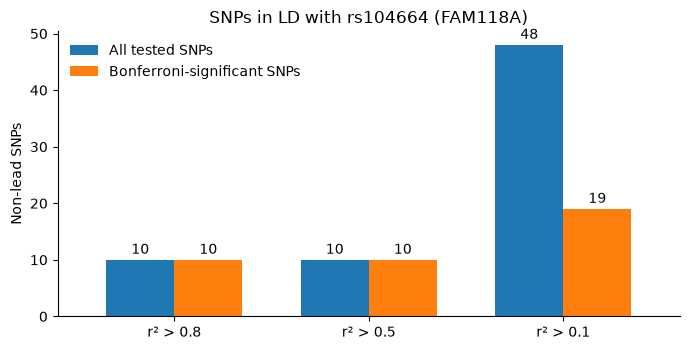

In [69]:
fig, ax = plt.subplots(figsize=(7, 3.6))
w6_counts.plot.bar(ax=ax, rot=0, color=['C0', 'C1'], width=0.7)
for container in ax.containers:
    ax.bar_label(container, padding=2)
ax.set(ylabel='Non-lead SNPs', title=f'SNPs in LD with {w6_lead["SNP"]} ({w6_symbol})')
ax.spines[['top', 'right']].set_visible(False)
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(w6 / f'{w6_symbol}_ld_counts.png', dpi=180)
plt.show()

**Reading the counts:** the r² > 0.8 and r² > 0.5 counts are both 10, and this is a real
result. No SNP falls between 0.5 and 0.8, because the values jump from 0.3078 to 0.8647.
The 10 high-LD SNPs are all significant, while 29 of the 38 SNPs with r² between 0.1 and
0.5 are not.

The 8 significant SNPs with r² ≤ 0.1 sit near the gene, with p around 10⁻⁸. Very strong
signals can carry over even through weak LD, so these may simply tag the main signal. We
did not run a conditional analysis, so a second independent signal is neither shown nor
ruled out.

### Step 7: Generate the LocusZoom Figure

We use [LocusZoom.js 0.14.0](https://statgen.github.io/locuszoom/docs/guides/data_retrieval.html) with our own data, so the page works offline. Compared with the standard layout, the significance line is the chromosome 22 cutoff, every SNP is drawn, the gene track uses GENCODE v12, and the recombination track and LD population menu are removed.

Re-rendering the PNG needs Playwright. Without it, the saved PNG is kept.

In [70]:
w6_html = w6 / f'{w6_symbol}_locuszoom.html'
w6_png = w6 / f'{w6_symbol}_locuszoom.png'
w6_drawn_path = w6 / f'{w6_symbol}_locuszoom_drawn_points.json'
write_locuszoom_page(w6_html, w6 / 'locuszoom_vendor', w6_ld_table, gene_track(gtf6, w6_annotation, '22', w6_start, w6_end),
    '22', w6_start, w6_end, w6_symbol, w6_gene_id, w6_lead['SNP'], w6_lead['POS'], w6_lead['P'], w6_cutoff, len(w6_ids))
print('Interactive page:', w6_html, f'({w6_html.stat().st_size / 1e6:.2f} MB, works offline)')

render6 = subprocess.run([os.environ.get('LOCUSZOOM_PYTHON', sys.executable), 'scripts/render_locuszoom.py',
                          str(w6_html), str(w6_png), str(w6_drawn_path)], capture_output=True, text=True)
print(render6.stdout.strip() if render6.returncode == 0 else
      'Playwright is not available in this Python, so the saved PNG was not re-rendered.')

Interactive page: data/week6_results/FAM118A_locuszoom.html (0.60 MB, works offline)
Playwright is not available in this Python, so the saved PNG was not re-rendered.


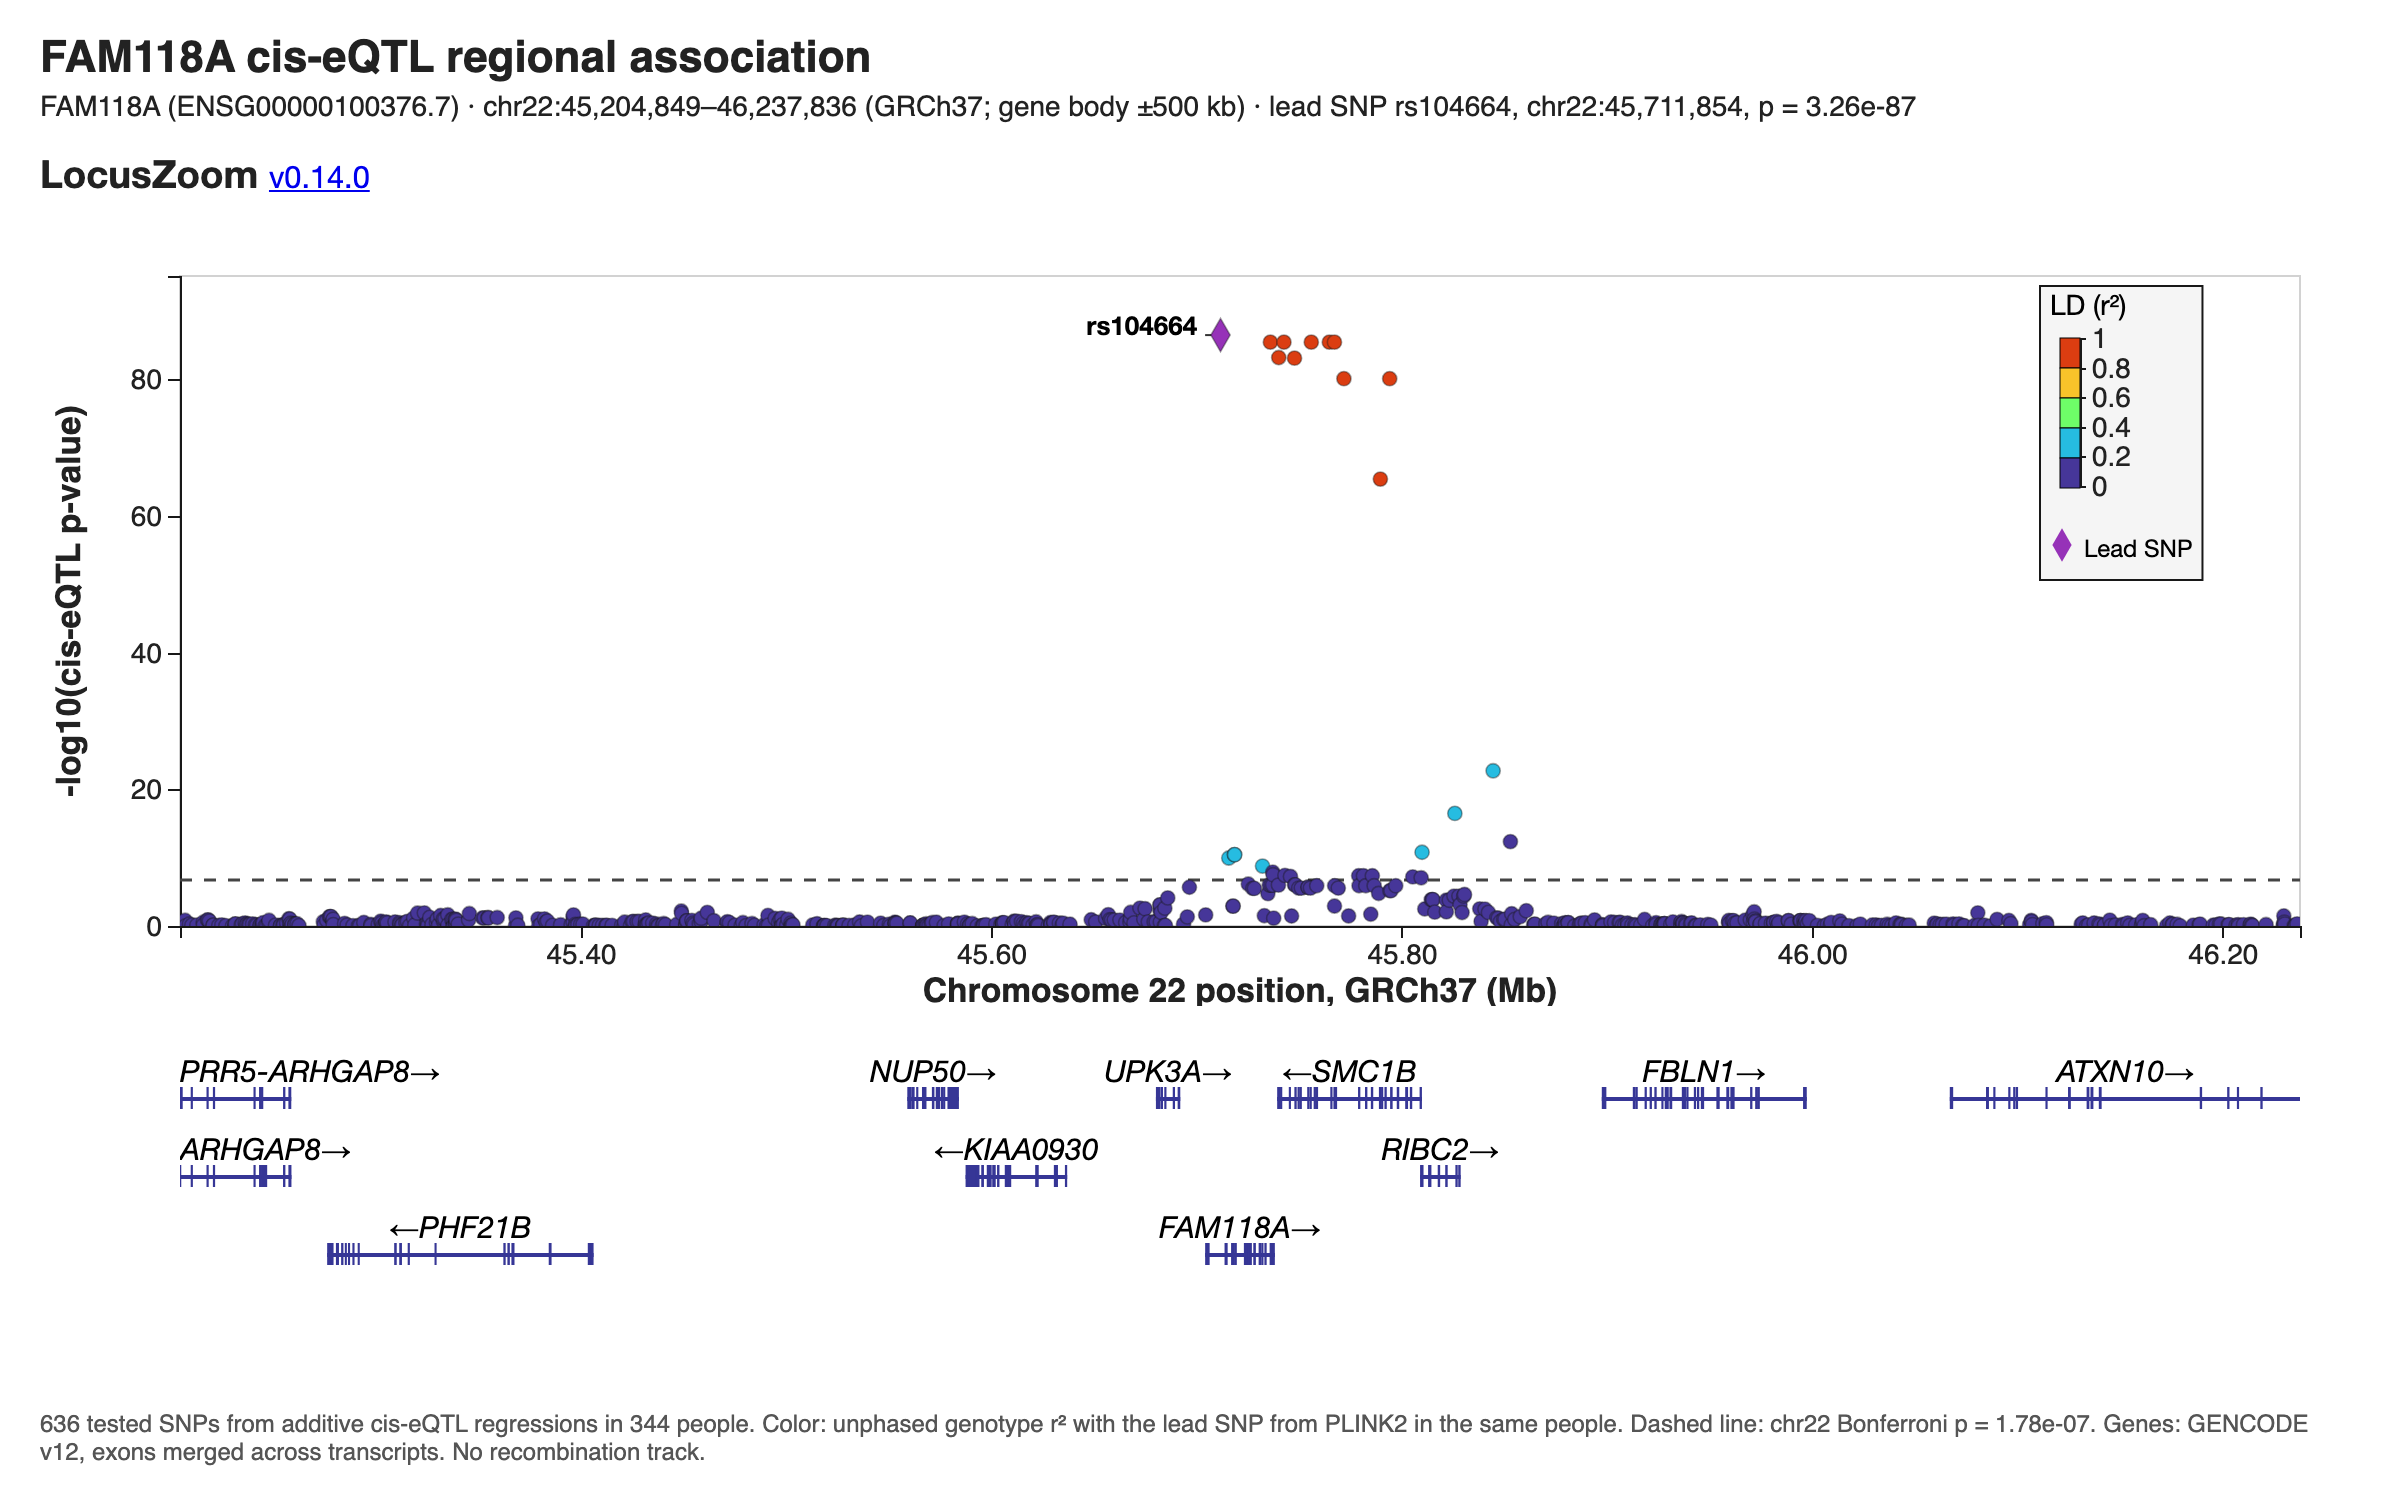

In [71]:
display(Image(filename=str(w6_png), width=1000))

### Step 8: Verify the Results

The drawing checks use values read back from the rendered plot.

In [72]:
drawn6 = json.loads(w6_drawn_path.read_text())
drawn_table6 = pd.DataFrame(drawn6['points']).set_index('SNP').sort_index()
saved6 = pd.read_csv(ld_table_path6, sep='\t').set_index('SNP').sort_index()
assert drawn6['problems'] == [] and drawn6['outside_requests'] == []
assert drawn_table6.index.equals(saved6.index)
expected_fill6 = np.array([f'rgb({r}, {g}, {b})' for r, g, b in ld_rgb6])[np.digitize(saved6['LD_R2'], ld_breaks6) - 1]
expected_fill6[saved6['Lead_SNP'].to_numpy()] = '#9632b8'

y6 = w6_expression.loc[w6_gene_id, w6_ids].to_numpy(float)
lead_check6 = linregress(lead_dosage6, y6)
beta6 = np.cov(lead_dosage6, y6, ddof=1)[0, 1] / lead_dosage6.var(ddof=1)
residuals6 = y6 - y6.mean() - beta6 * (lead_dosage6 - lead_dosage6.mean())
se6 = np.sqrt((residuals6 ** 2).sum() / (len(y6) - 2) / ((lead_dosage6 - lead_dosage6.mean()) ** 2).sum())
manual_p6 = 2 * t_distribution.sf(abs(beta6 / se6), len(y6) - 2)

park7_id, park7_start, park7_end = 'ENSG00000116288.8', 8014351, 8045565
chr1_expression6 = pd.concat([c.loc[c['TargetID'].eq(park7_id)] for c in pd.read_csv('data/GD462.GeneQuantRPKM.50FN.samplename.resk10.txt',
    sep='\t', usecols=['TargetID', *w6_ids], chunksize=2000)]).set_index('TargetID').loc[park7_id, w6_ids].astype(float)
chr1_block6 = pd.concat([b.loc[b['POS'].between(park7_start - 500000, park7_end + 500000)]
    for b in pd.read_csv('data/week4_results/chr1_matched.traw', sep=r'\s+', chunksize=2000)])
refit6 = fit_cis(chr1_block6, w6_ids, chr1_expression6, w6_column).set_index('SNP').sort_index()
week4_park76 = pd.concat([c.loc[c['Gene_ID'].eq(park7_id)] for c in pd.read_csv('data/week4_results/chr1_cis_eqtl.tsv.gz',
    sep='\t', chunksize=200000)]).set_index('SNP').sort_index()

checks6 = {
    'Chromosome 22 only in associations and LD pairs': w6_associations['CHR'].eq(22).all() and ld_pairs6['#CHROM_A'].eq(22).all() and ld_pairs6['CHROM_B'].eq(22).all(),
    'Same gene and lead SNP used for counts, table, and plot': drawn_table6['Lead_SNP'].sum() == 1 and drawn_table6.index[drawn_table6['Lead_SNP']][0] == w6_lead['SNP'] and saved6.loc[w6_lead['SNP'], 'Lead_SNP'],
    'Regression code reproduces Week 4 PARK7 p-values': refit6.index.equals(week4_park76.index) and np.allclose(refit6['P'], week4_park76['P'], rtol=1e-9, atol=0),
    'Lead p-value matches a hand-written OLS t-test': np.isclose(manual_p6, w6_lead['P'], rtol=1e-6) and np.isclose(lead_check6.pvalue, w6_lead['P'], rtol=1e-9),
    'Lead SNP has the smallest p-value in the locus': w6_lead['P'] == saved6['P'].min(),
    'Drawn x and y data match the saved table': np.array_equal(drawn_table6['Position'], saved6['Position']) and np.allclose(drawn_table6['Minus_Log10_P'], saved6['Minus_Log10_P'], rtol=1e-12),
    'Drawn pixel positions convert back to the data': (drawn_table6['Pixel_position'] - saved6['Position']).abs().max() < 1 and (drawn_table6['Pixel_minus_log10_p'] - saved6['Minus_Log10_P']).abs().max() < 1e-6,
    'Drawn colors match the LD bins in the saved table': (drawn_table6['Fill'].to_numpy() == expected_fill6).all(),
    'Drawn r² matches the saved table': np.allclose(drawn_table6['LD_R2'], saved6['LD_R2'], rtol=1e-12),
    'Counts recompute from the saved table': w6_counts['All tested SNPs'].tolist() == [int((saved6['LD_R2'].gt(t) & ~saved6['Lead_SNP']).sum()) for t in w6_thresholds],
    'Plot shows the whole cis-window': drawn6['state']['start'] == w6_start and drawn6['state']['end'] == w6_end and list(map(int, drawn6['x_extent'])) == [w6_start, w6_end],
    'All tested SNPs fall inside the plotted window': saved6['Position'].between(w6_start, w6_end).all(),
    f'{w6_symbol} appears in the gene track': w6_symbol in drawn6['genes'],
    'Written answers match these results': (w6_tests, len(significant6), significant6['Gene_ID'].nunique(), w6_symbol, w6_lead['SNP']) == (280657, 1316, 72, 'FAM118A', 'rs104664') and w6_counts['All tested SNPs'].tolist() == [10, 10, 48] and w6_counts['Bonferroni-significant SNPs'].tolist() == [10, 10, 19],
}
failed6 = [name for name, passed in checks6.items() if not passed]
assert not failed6, failed6
print(f'All {len(checks6)} checks passed.')

All 14 checks passed.


**Findings:** see Week 6 in [weekly_tasks_results.md](../weekly_tasks_results.md).